In [1]:
# importing needed packages
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# read in the cleaned CSV with data from central valley stations
path = 'D:/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
if os.path.exists(path):
    CV_rows = pd.read_csv(path, low_memory = False)
else:
    path = '/Volumes/disk1/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
    CV_rows = pd.read_csv(path, low_memory = False)

print(CV_rows)

           STATION_ID         STATION                 DATE  year  month  day  \
0         USW00023155  BAKERSFIELD AP  1928-01-01 02:00:00  1928      1    1   
1         USW00023155  BAKERSFIELD AP  1928-01-01 05:00:00  1928      1    1   
2         USW00023155  BAKERSFIELD AP  1928-01-01 08:00:00  1928      1    1   
3         USW00023155  BAKERSFIELD AP  1928-01-01 09:00:00  1928      1    1   
4         USW00023155  BAKERSFIELD AP  1928-01-01 11:00:00  1928      1    1   
...               ...             ...                  ...   ...    ...  ...   
10131269  USW00023202  TRAVIS FLD AFB  2026-09-28 02:55:00  2026      9   28   
10131270  USW00023202  TRAVIS FLD AFB  2026-09-28 03:55:00  2026      9   28   
10131271  USW00023202  TRAVIS FLD AFB  2026-09-28 04:55:00  2026      9   28   
10131272  USW00023202  TRAVIS FLD AFB  2026-09-28 05:55:00  2026      9   28   
10131273  USW00023202  TRAVIS FLD AFB  2026-09-28 06:55:00  2026      9   28   

          hour  minute  LATITUDE  LONGI

In [3]:
# #Remove duplicate hours for each station
# CV_rows = CV_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])

# print(CV_rows.shape)

In [4]:
# Exclude days from April through October (months 4-10) in CV_rows
CV_rows = CV_rows[~CV_rows['month'].isin([4, 5, 6, 7, 8, 9, 10])]

print("CV_rows after removing April-October:", CV_rows.shape)

CV_rows after removing April-October: (4402517, 16)


In [5]:
# Keep only rows with defined nonzero precipitation values
CV_precip_rows = CV_rows[(CV_rows['HourlyPrecipitation'].notna()) & (CV_rows['HourlyPrecipitation'] >= 0.03)]

print("CV_precip_rows after keeping nonzero precipitation values:", CV_precip_rows.shape)

CV_precip_rows after keeping nonzero precipitation values: (124345, 16)


In [6]:
CV_precip_rows.head(20)

,STATION_ID,STATION,DATE,year,month,day,hour,minute,LATITUDE,LONGITUDE,HourlyDryBulbTemperature,HourlyDewPointTemperature,HourlyWindDirection,HourlyWindSpeed,HourlyPrecipitation,HourlyVisibility
168536,USW00023155,BAKERSFIELD AP,1948-12-03 15:00:00,1948,12,3,15,0,35.4342,-119.0553,6.1,4.4,360.0,8.2,1.5,9.6
168537,USW00023155,BAKERSFIELD AP,1948-12-03 16:00:00,1948,12,3,16,0,35.4342,-119.0553,6.1,3.9,90.0,3.6,0.8,16.0
168542,USW00023155,BAKERSFIELD AP,1948-12-03 21:00:00,1948,12,3,21,0,35.4342,-119.0553,5.6,4.4,225.0,3.6,0.3,16.0
168599,USW00023155,BAKERSFIELD AP,1948-12-06 06:00:00,1948,12,6,6,0,35.4342,-119.0553,6.7,6.1,315.0,3.6,0.5,4.8
168600,USW00023155,BAKERSFIELD AP,1948-12-06 07:00:00,1948,12,6,7,0,35.4342,-119.0553,6.7,5.6,270.0,3.6,1.3,6.4
168798,USW00023155,BAKERSFIELD AP,1948-12-14 13:00:00,1948,12,14,13,0,35.4342,-119.0553,10.0,2.8,NaN,0.0,0.3,16.0
168804,USW00023155,BAKERSFIELD AP,1948-12-14 19:00:00,1948,12,14,19,0,35.4342,-119.0553,5.6,3.3,315.0,1.5,0.8,16.0
169093,USW00023155,BAKERSFIELD AP,1948-12-26 20:00:00,1948,12,26,20,0,35.4342,-119.0553,8.3,6.1,293.0,3.6,0.3,16.0
169094,USW00023155,BAKERSFIELD AP,1948-12-26 21:00:00,1948,12,26,21,0,35.4342,-119.0553,8.3,5.6,90.0,1.0,0.5,16.0
169095,USW00023155,BAKERSFIELD AP,1948-12-26 22:00:00,1948,12,26,22,0,35.4342,-119.0553,8.3,6.1,113.0,8.2,1.3,16.0


In [5]:
CV_vis_rows = CV_rows[CV_rows['HourlyVisibility'].notna()]

print("CV_vis_rows after keeping defined visibility values:", CV_vis_rows.shape)

CV_vis_rows after keeping defined visibility values: (4214230, 16)


In [7]:
# Drop duplicate hours for each station
CV_precip_rows = CV_precip_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])
CV_vis_rows = CV_vis_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])

print(CV_precip_rows.shape)
print(CV_vis_rows.shape)

(88595, 16)
(3324382, 16)


In [8]:
CV_precip_rows


,STATION_ID,STATION,DATE,year,month,day,hour,minute,LATITUDE,LONGITUDE,HourlyDryBulbTemperature,HourlyDewPointTemperature,HourlyWindDirection,HourlyWindSpeed,HourlyPrecipitation,HourlyVisibility
168536,USW00023155,BAKERSFIELD AP,1948-12-03 15:00:00,1948,12,3,15,0,35.4342,-119.0553,6.1,4.4,360.0,8.2,1.5,9.60
168537,USW00023155,BAKERSFIELD AP,1948-12-03 16:00:00,1948,12,3,16,0,35.4342,-119.0553,6.1,3.9,90.0,3.6,0.8,16.00
168542,USW00023155,BAKERSFIELD AP,1948-12-03 21:00:00,1948,12,3,21,0,35.4342,-119.0553,5.6,4.4,225.0,3.6,0.3,16.00
168599,USW00023155,BAKERSFIELD AP,1948-12-06 06:00:00,1948,12,6,6,0,35.4342,-119.0553,6.7,6.1,315.0,3.6,0.5,4.80
168600,USW00023155,BAKERSFIELD AP,1948-12-06 07:00:00,1948,12,6,7,0,35.4342,-119.0553,6.7,5.6,270.0,3.6,1.3,6.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10126776,USW00023202,TRAVIS FLD AFB,2026-03-31 13:55:00,2026,3,31,13,55,38.2667,-121.9333,20.8,11.4,210.0,4.6,0.3,16.00
10126778,USW00023202,TRAVIS FLD AFB,2026-03-31 15:55:00,2026,3,31,15,55,38.2667,-121.9333,15.1,12.8,250.0,8.2,0.8,8.05
10126779,USW00023202,TRAVIS FLD AFB,2026-03-31 16:55:00,2026,3,31,16,55,38.2667,-121.9333,15.9,13.0,250.0,6.7,0.3,16.00
10126780,USW00023202,TRAVIS FLD AFB,2026-03-31 17:55:00,2026,3,31,17,55,38.2667,-121.9333,14.9,12.7,240.0,7.2,0.5,14.48


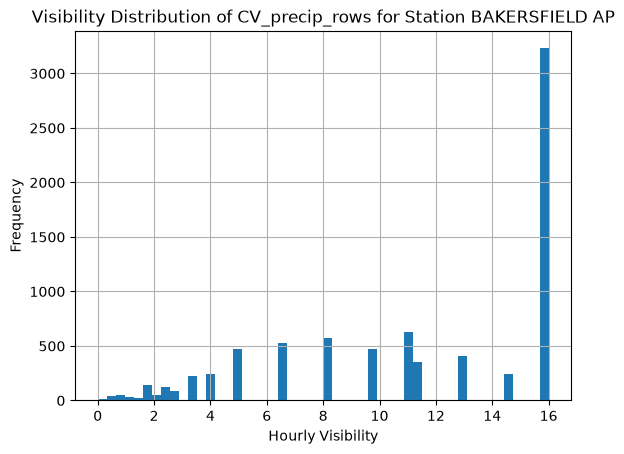

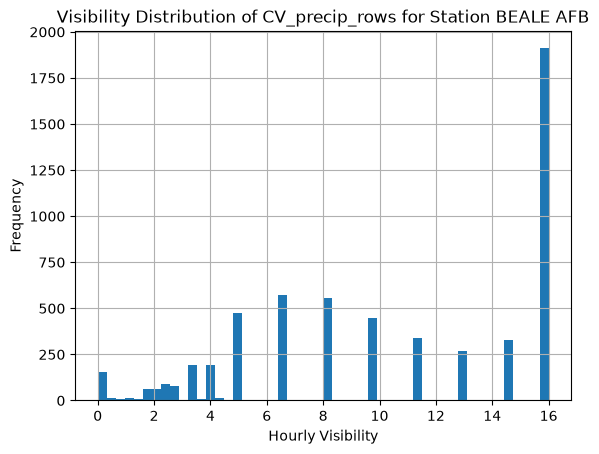

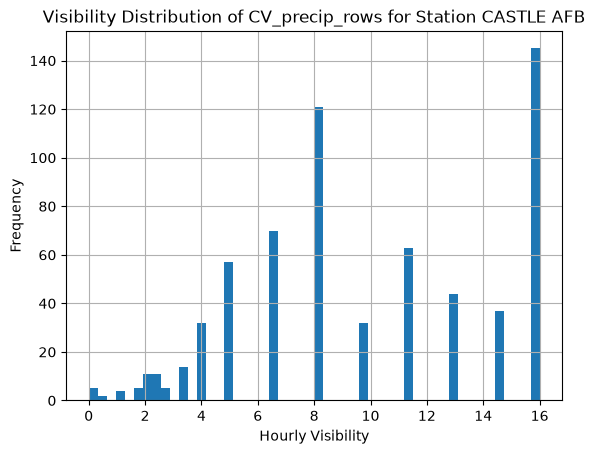

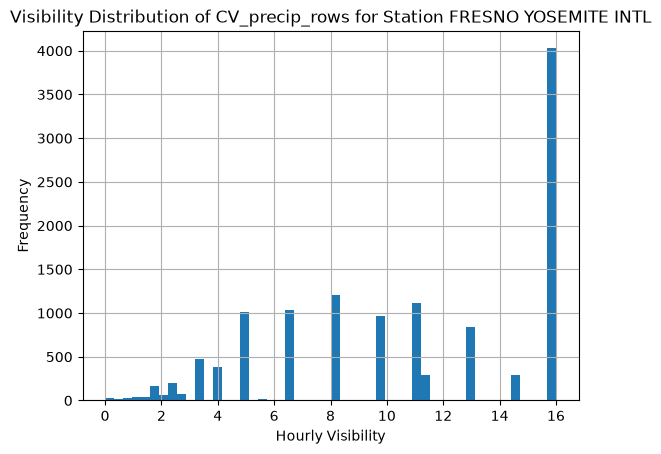

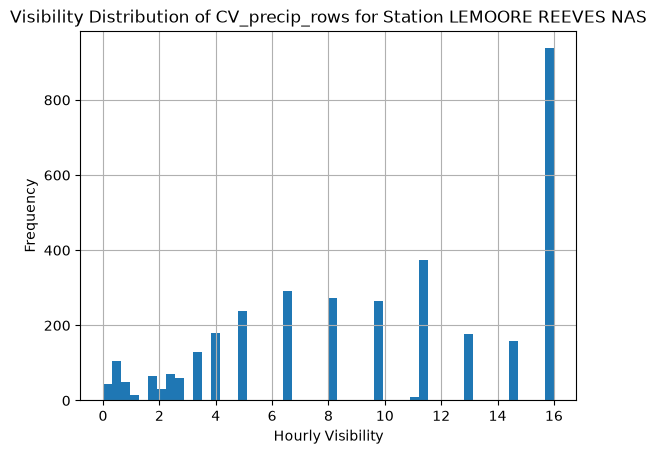

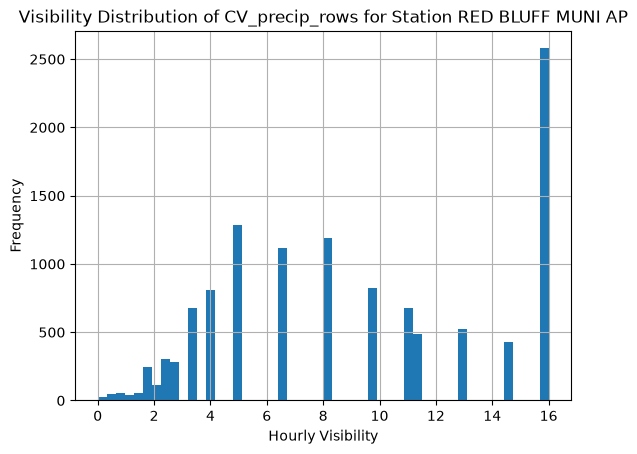

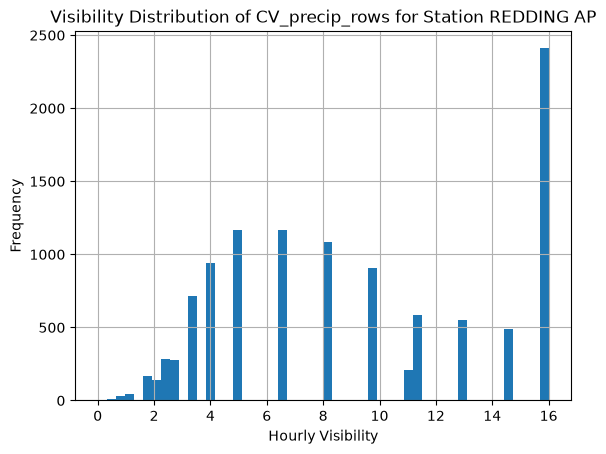

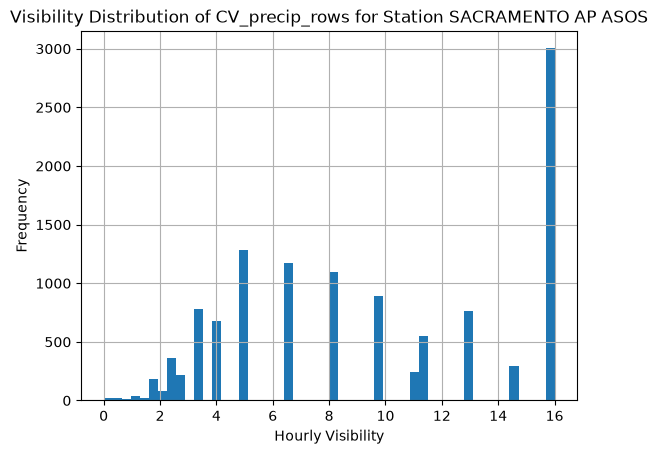

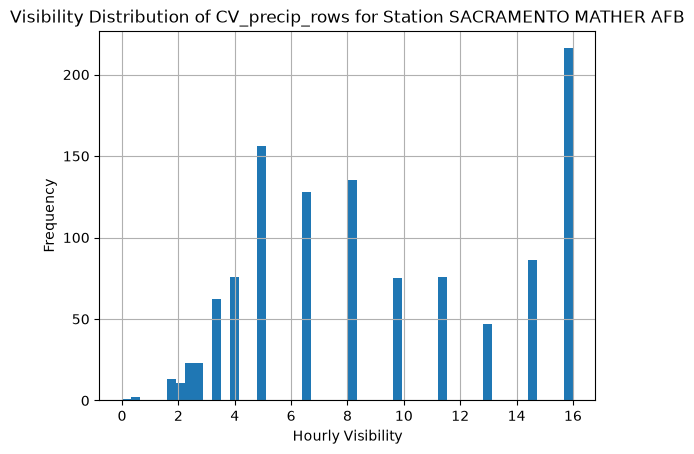

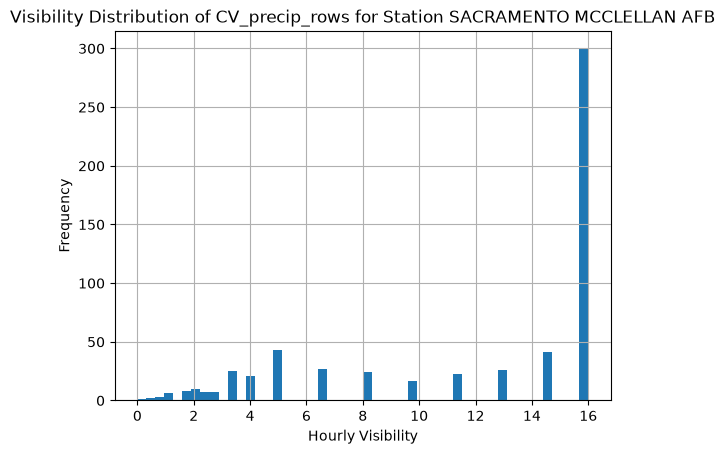

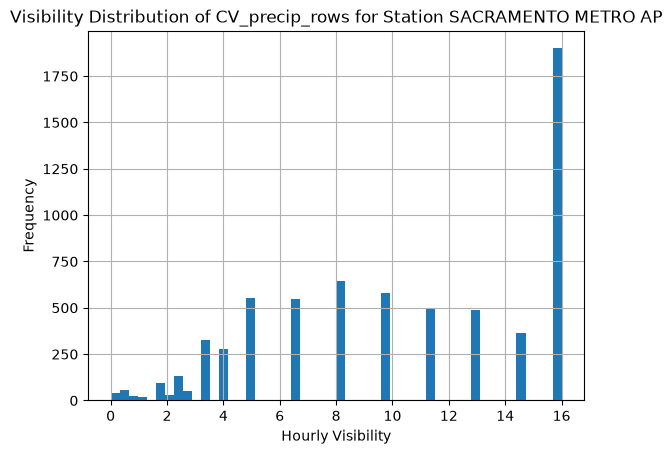

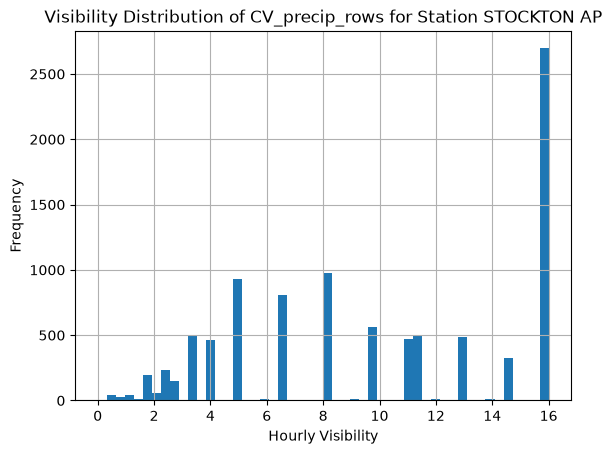

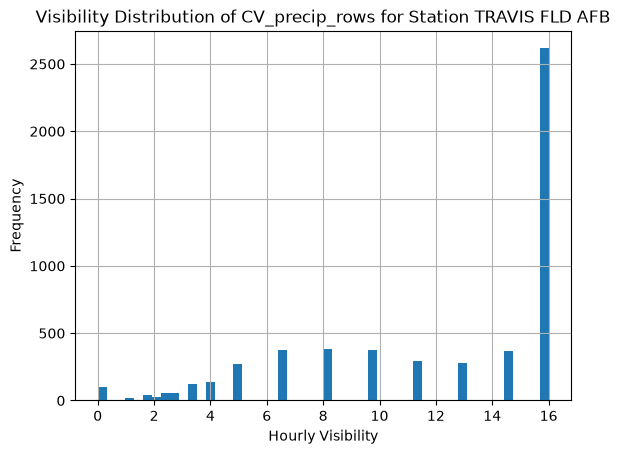

In [9]:
#Show visibility distribution of CV_precip_rows by individual station
for station in CV_precip_rows['STATION'].unique():
    CV_precip_rows[CV_precip_rows['STATION'] == station]['HourlyVisibility'].hist(bins=50)
    plt.xlabel('Hourly Visibility')
    plt.ylabel('Frequency')
    plt.title(f'Visibility Distribution of CV_precip_rows for Station {station}')
    plt.show()

CV_precip_lowvis: (1089, 16)


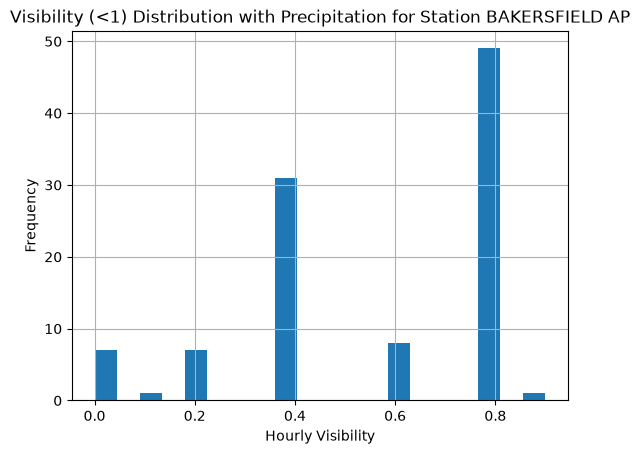

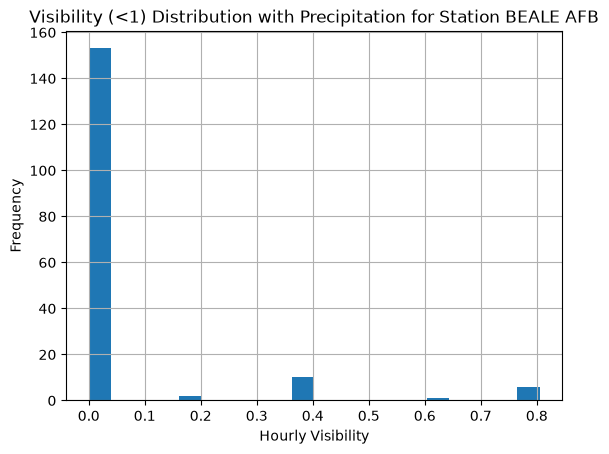

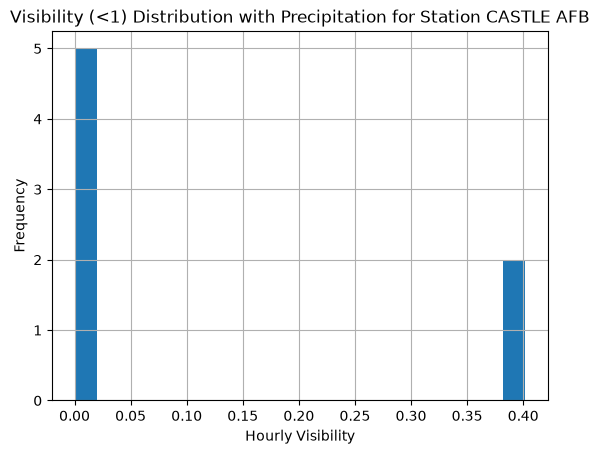

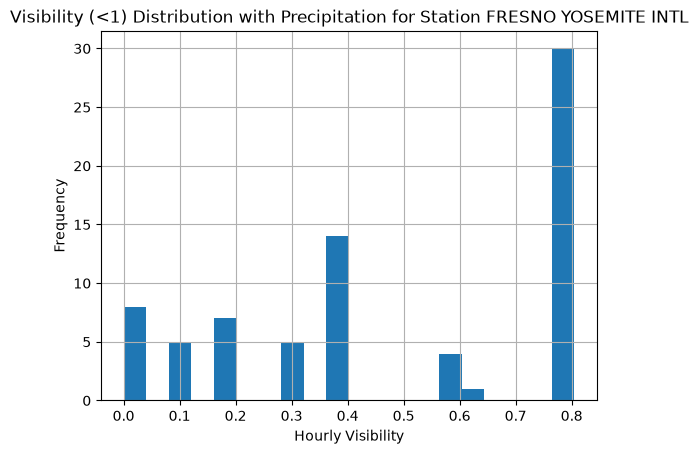

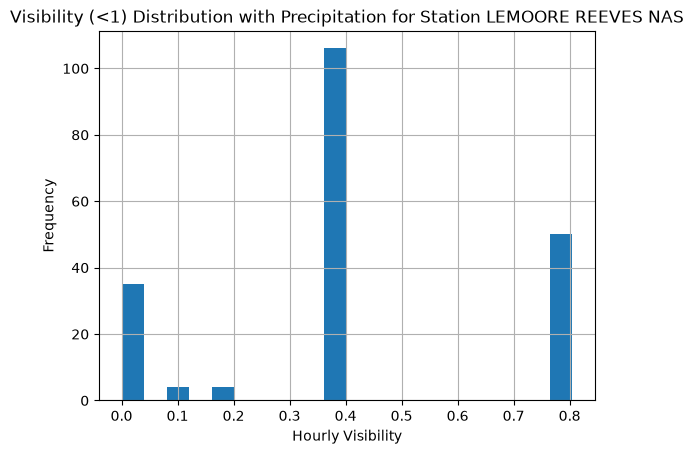

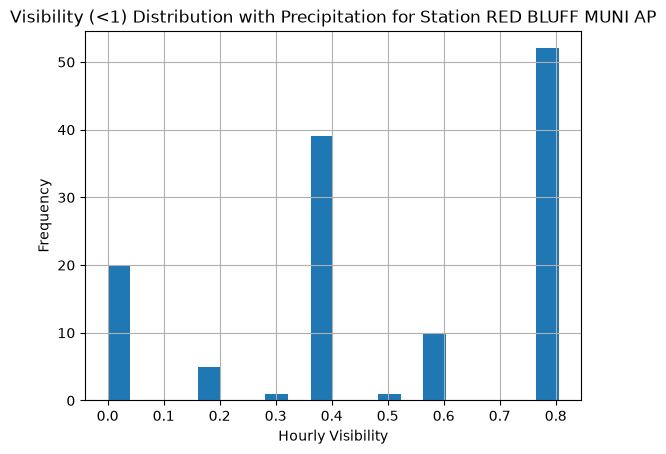

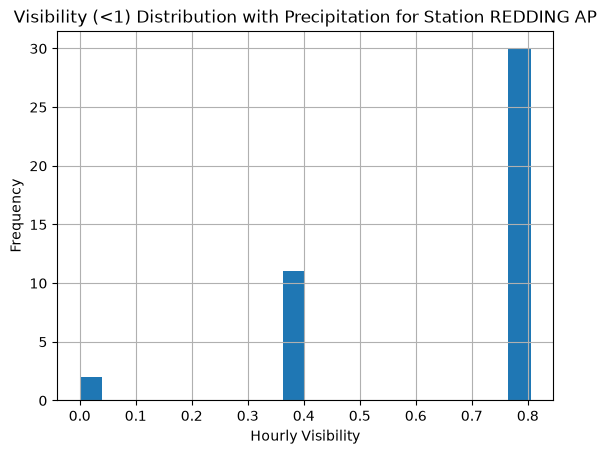

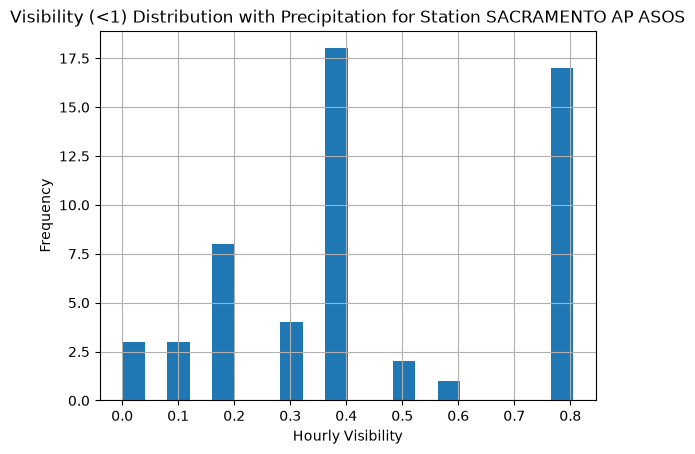

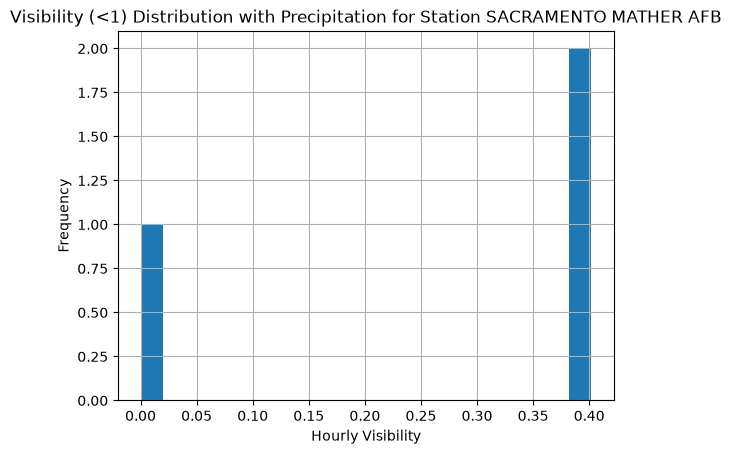

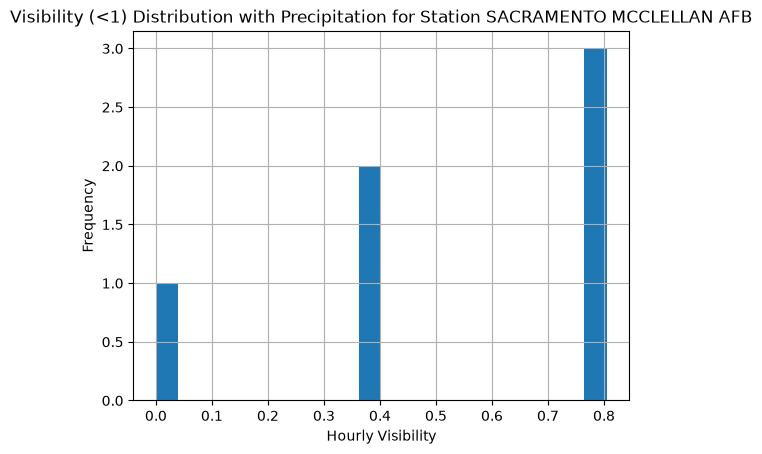

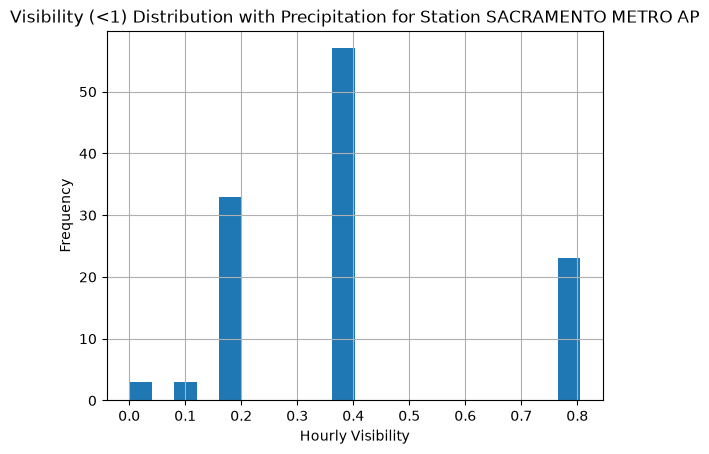

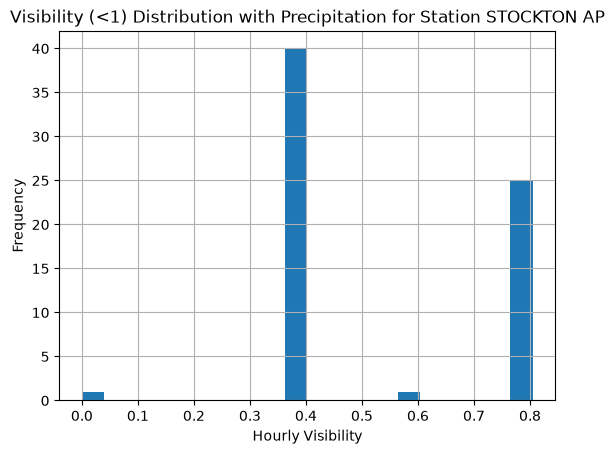

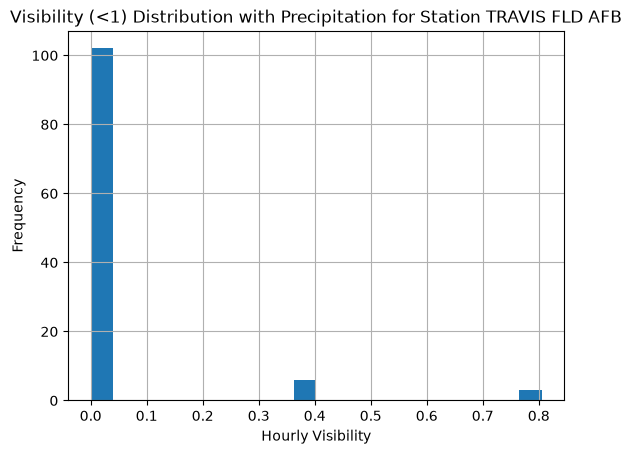

In [10]:
# Identify rows with visibility < 1
CV_precip_lowvis = CV_precip_rows[CV_precip_rows['HourlyVisibility'] < 1]
print("CV_precip_lowvis:", CV_precip_lowvis.shape)

# Plot histogram of HourlyVisibility for each station
for station in CV_precip_lowvis['STATION'].unique():
    CV_precip_lowvis[CV_precip_lowvis['STATION'] == station]['HourlyVisibility'].hist(bins=20)
    plt.xlabel('Hourly Visibility')
    plt.ylabel('Frequency')
    plt.title(f'Visibility (<1) Distribution with Precipitation for Station {station}')
    plt.show()

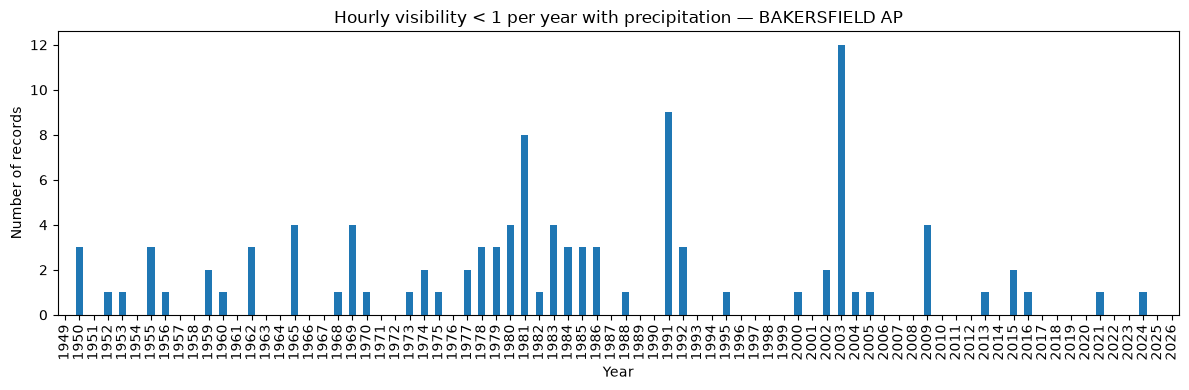

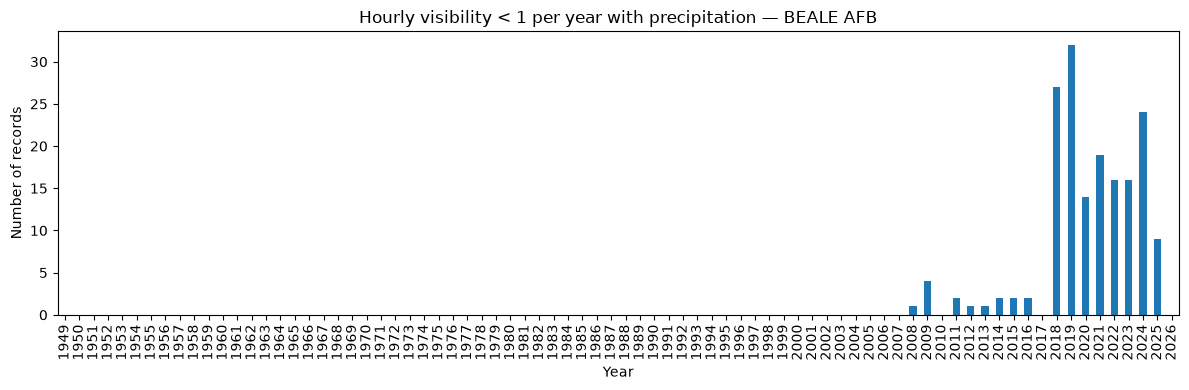

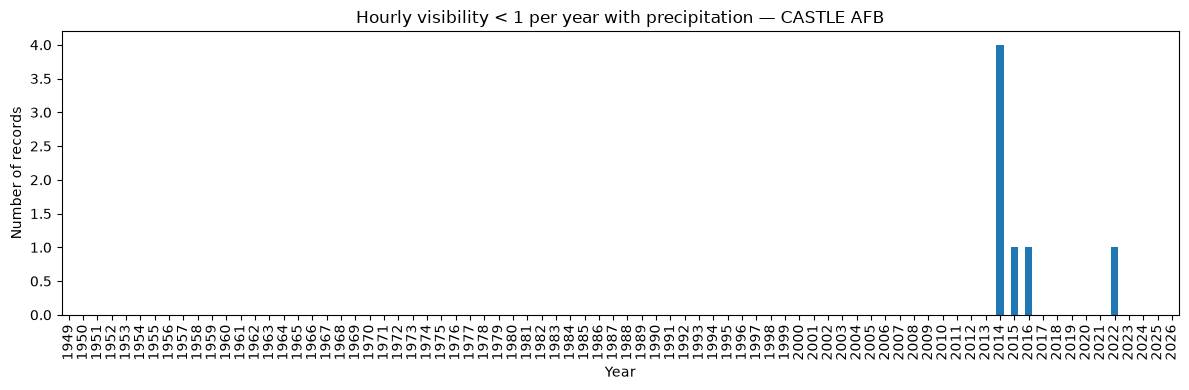

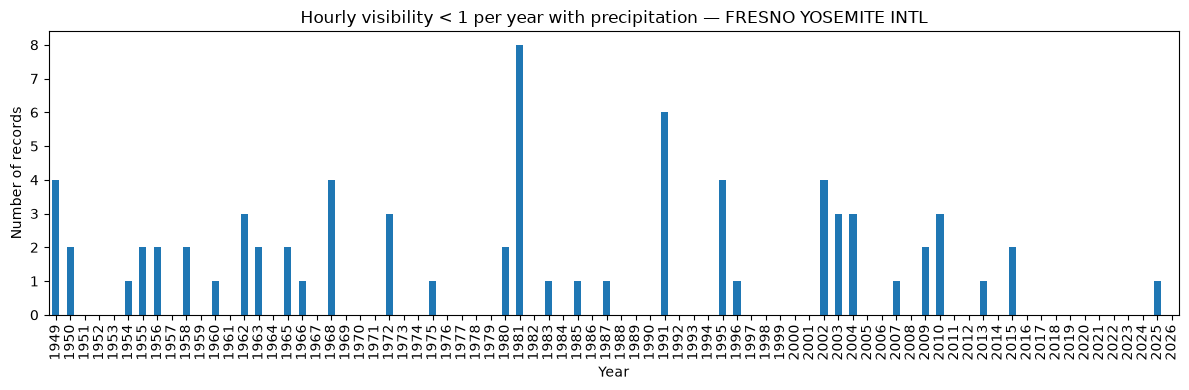

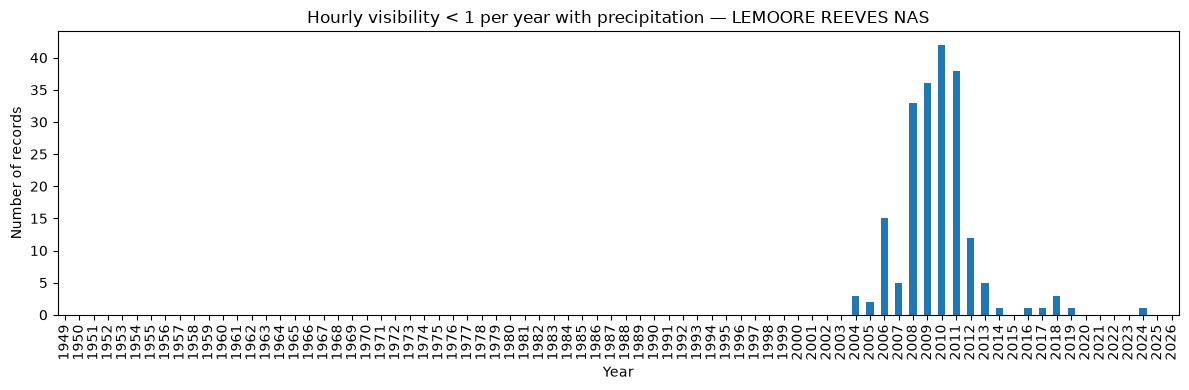

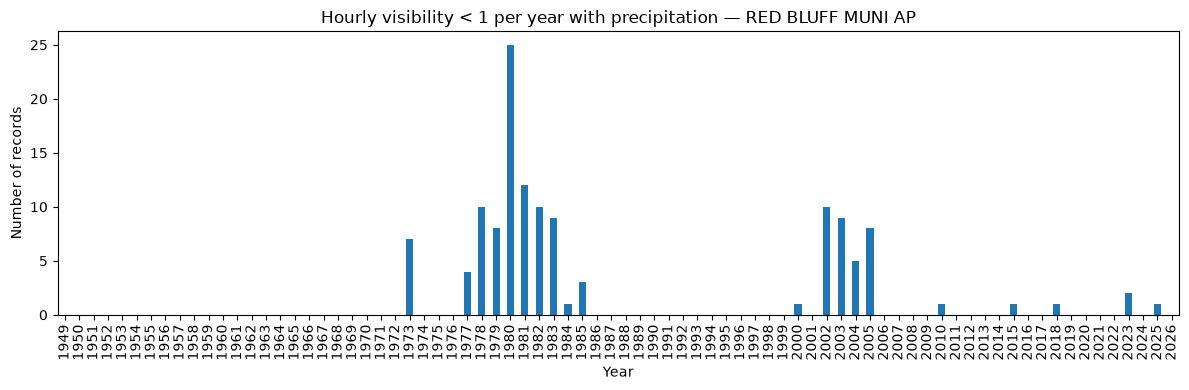

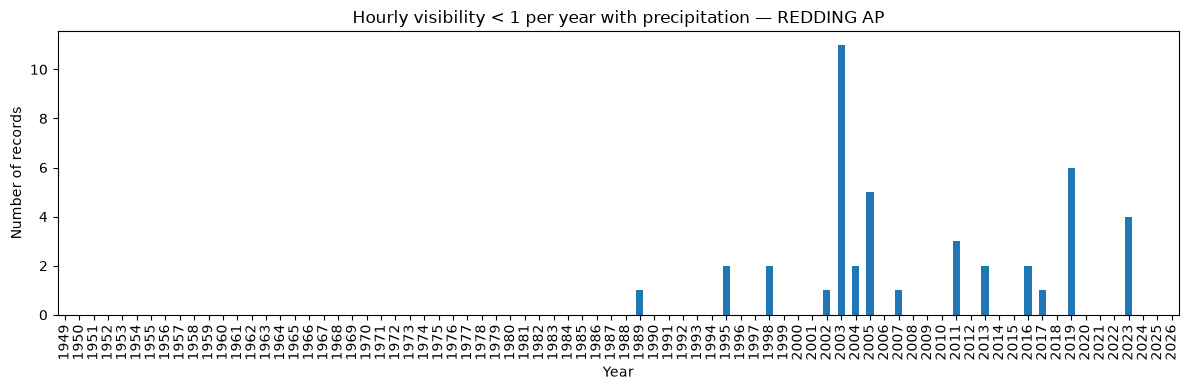

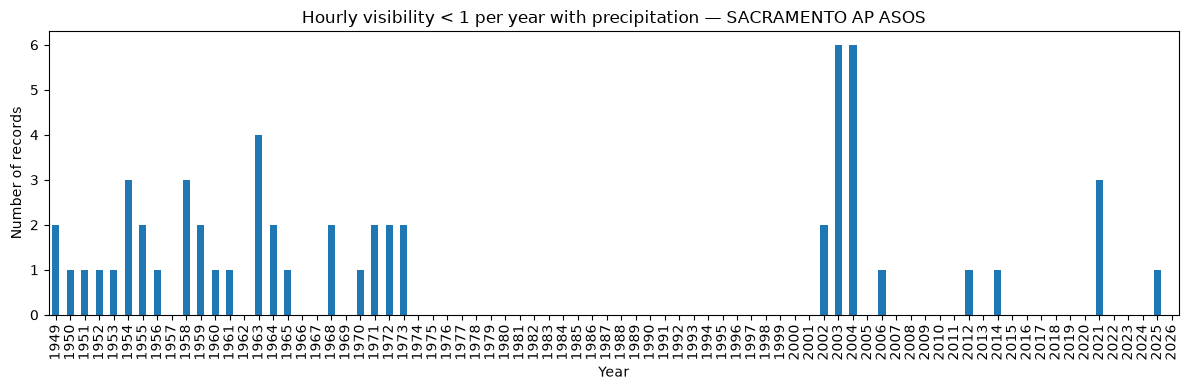

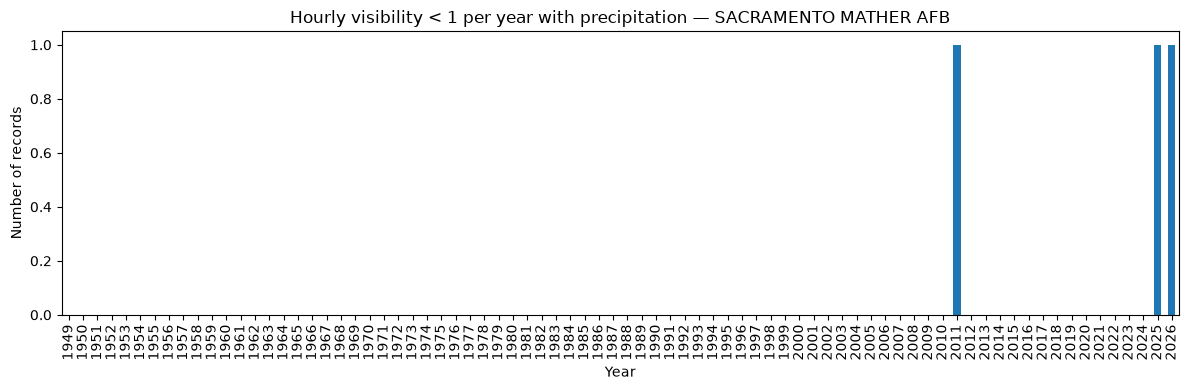

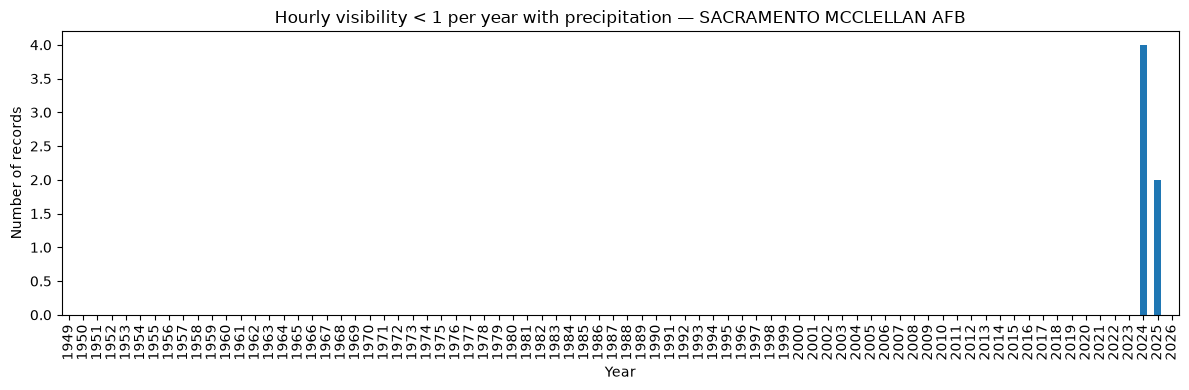

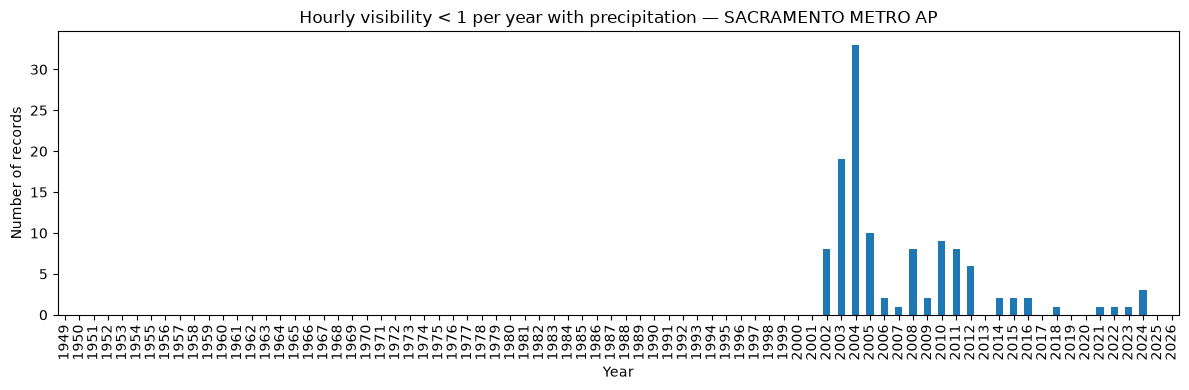

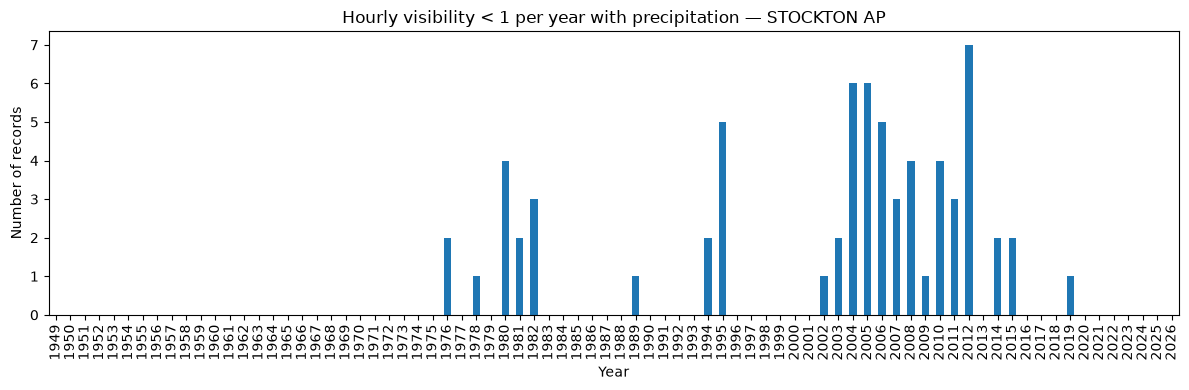

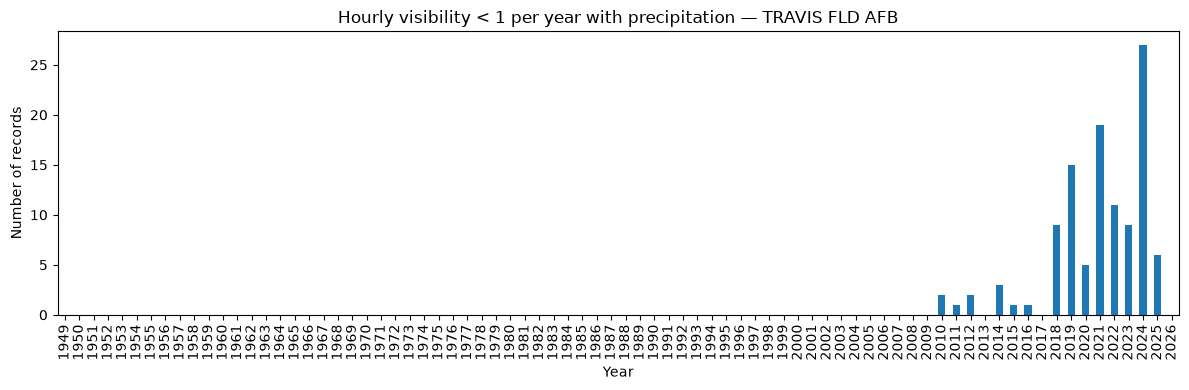

In [20]:
# Show missing years with empty bars in the annual counts plots
annual_counts = CV_precip_lowvis.groupby(['STATION', 'year']).size()

for station_name in CV_precip_lowvis['STATION'].unique():
    station_counts = annual_counts.loc[station_name].sort_index()
    all_years = range(CV_precip_lowvis['year'].min(), CV_precip_lowvis['year'].max() + 1)
    station_counts = station_counts.reindex(all_years, fill_value=0)   

    plt.figure(figsize=(12, 4))
    station_counts.plot(kind='bar')
    plt.xlabel('Year')
    plt.ylabel('Number of records')
    plt.title(f'Hourly visibility < 1 per year with precipitation — {station_name}')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [24]:
# determine overlapping times of precipitation and low visibility for each station
# overlapping means that there is both precipitation and low visibility recorded at the same time for a given station
precip = CV_precip_rows[['STATION', 'DATE', 'HourlyPrecipitation']].copy()
precip['DATE'] = pd.to_datetime(precip['DATE'])

# filter low visibility times (less than 1 km)
low_vis = CV_vis_rows.loc[
    CV_vis_rows['HourlyVisibility'].lt(1),
    ['STATION', 'DATE', 'HourlyVisibility']
].copy()
low_vis['DATE'] = pd.to_datetime(low_vis['DATE'])

matches = []

# Determine matches between precipitation and low visibility times for each station
# The times need to match to the same day for them to be considered overlapping
for station_name, precip_station in precip.groupby('STATION'):
    vis_station = low_vis[low_vis['STATION'] == station_name].sort_values('DATE')
    vis_times = vis_station['DATE'].to_numpy()

    # below we find all low visibility times that match the precipitation times on the same day
    #change this to determine overlap within 24 hours
    for row in precip_station.itertuples(index=False):
        start = np.searchsorted(vis_times, np.datetime64(row.DATE), side='left')
        end = np.searchsorted(
            vis_times,
            # this shows matching times within 24 hours
            np.datetime64(row.DATE + pd.Timedelta(hours=24)),
            side='right'
        )

        for vis_row in vis_station.iloc[start:end].itertuples(index=False):
            matches.append({
                'STATION': station_name,
                'precip_time': row.DATE,
                'HourlyPrecipitation': row.HourlyPrecipitation,
                'low_visibility_time': vis_row.DATE,
                'HourlyVisibility': vis_row.HourlyVisibility
            })

overlapping_times = pd.DataFrame(matches)
overlapping_times

,STATION,precip_time,HourlyPrecipitation,low_visibility_time,HourlyVisibility
0,BAKERSFIELD AP,1948-12-03 15:00:00,1.5,1948-12-04 05:00:00,0.400
1,BAKERSFIELD AP,1948-12-03 16:00:00,0.8,1948-12-04 05:00:00,0.400
2,BAKERSFIELD AP,1948-12-03 21:00:00,0.3,1948-12-04 05:00:00,0.400
3,BAKERSFIELD AP,1948-12-27 09:00:00,1.8,1948-12-28 05:00:00,0.200
4,BAKERSFIELD AP,1948-12-27 09:00:00,1.8,1948-12-28 08:00:00,0.100
...,...,...,...,...,...
40150,TRAVIS FLD AFB,2026-01-01 10:55:00,1.0,2026-01-02 08:10:00,0.604
40151,TRAVIS FLD AFB,2026-01-01 12:55:00,1.5,2026-01-02 08:10:00,0.604
40152,TRAVIS FLD AFB,2026-01-01 21:55:00,0.2,2026-01-02 08:10:00,0.604
40153,TRAVIS FLD AFB,2026-01-01 22:55:00,0.2,2026-01-02 08:10:00,0.604


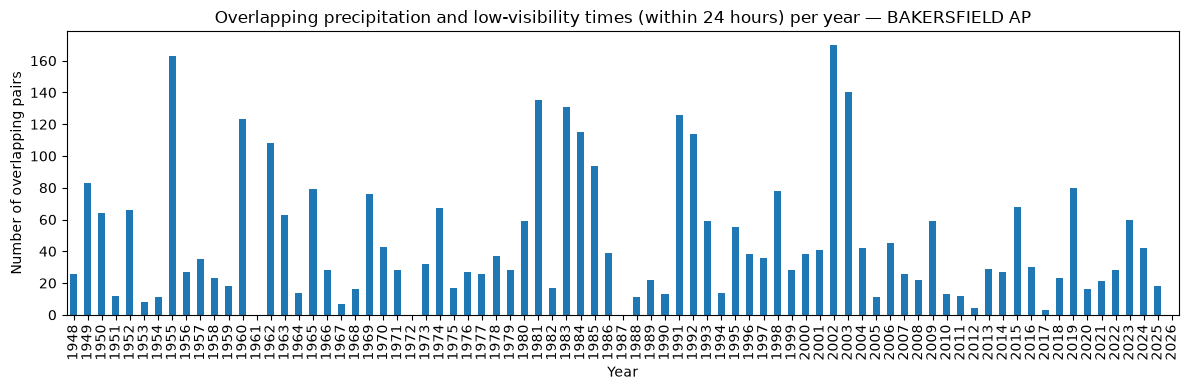

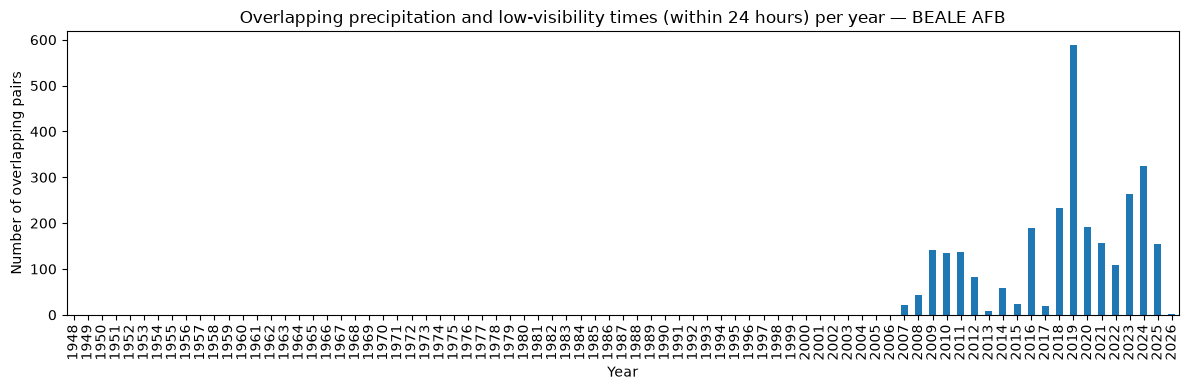

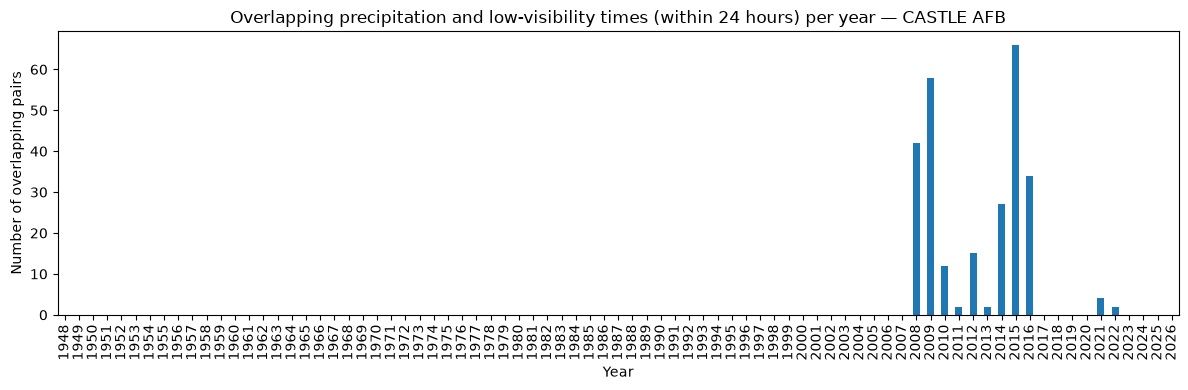

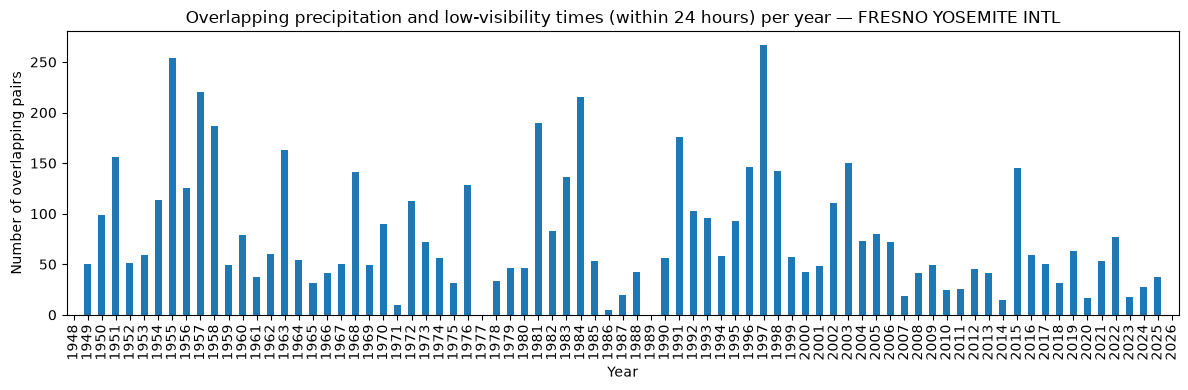

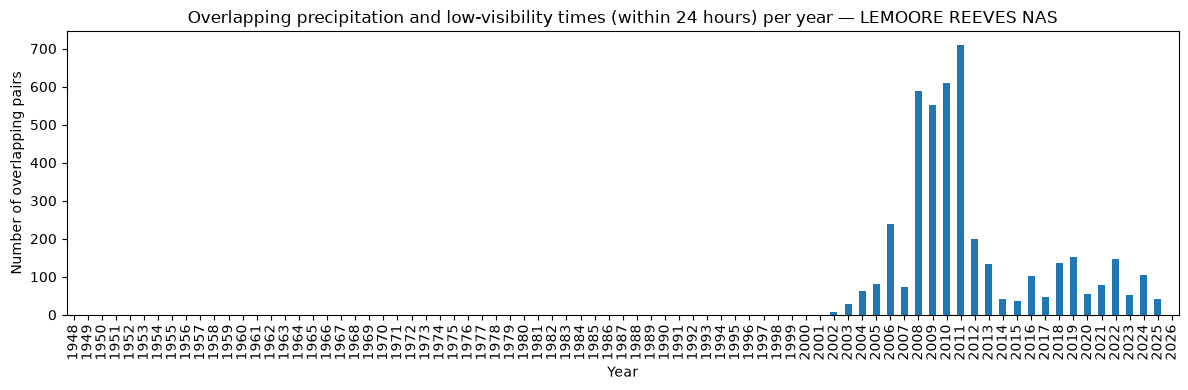

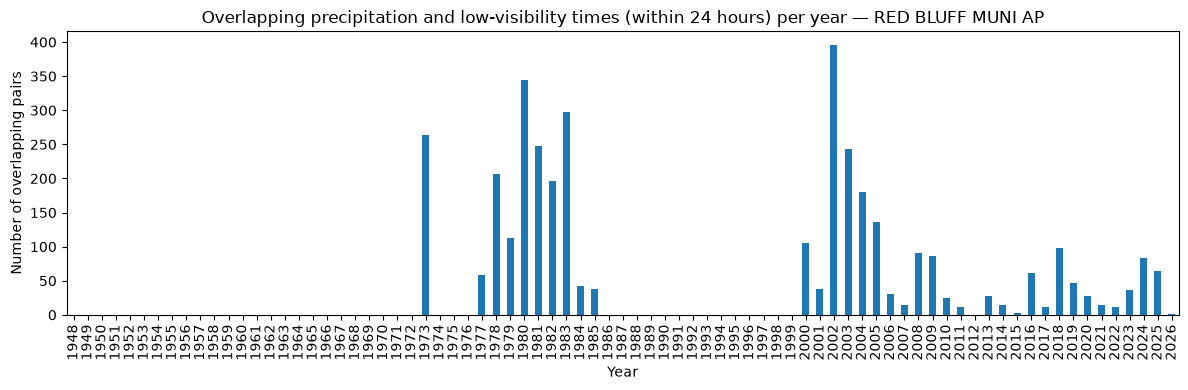

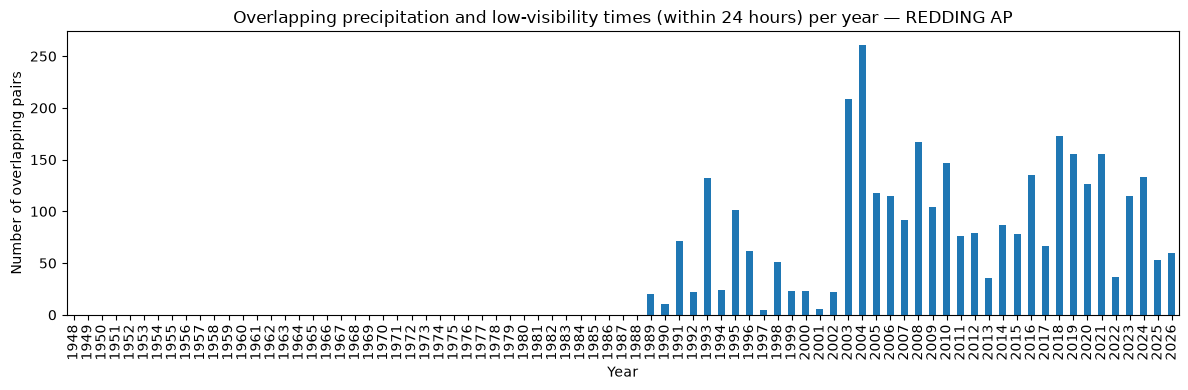

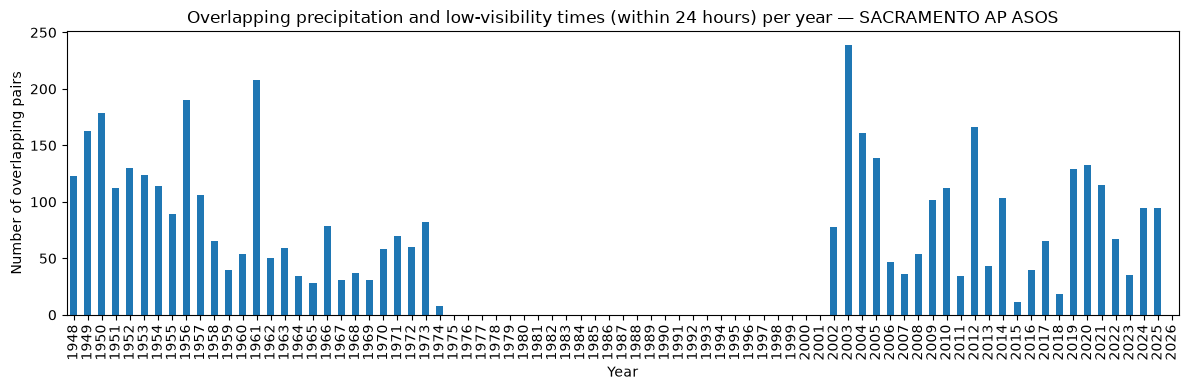

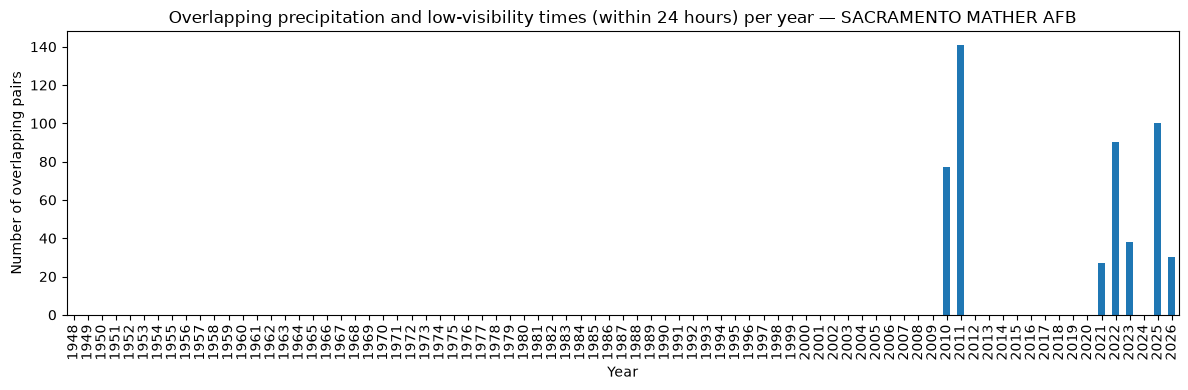

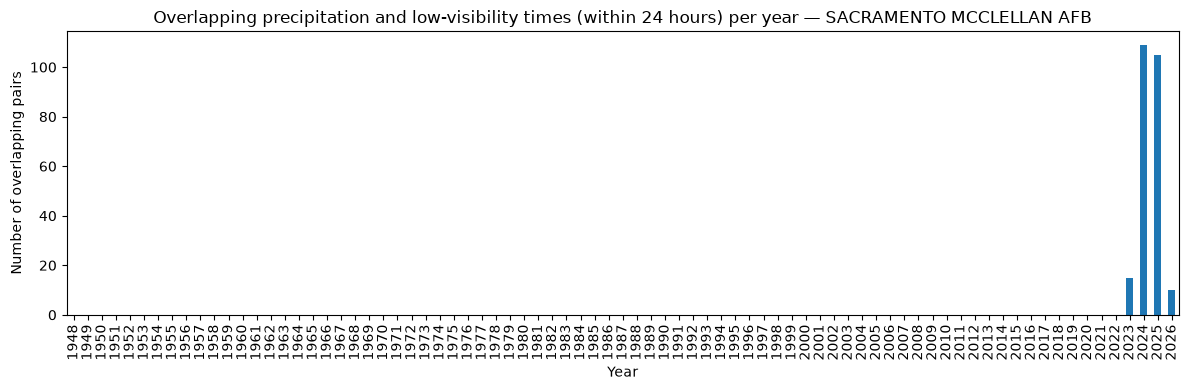

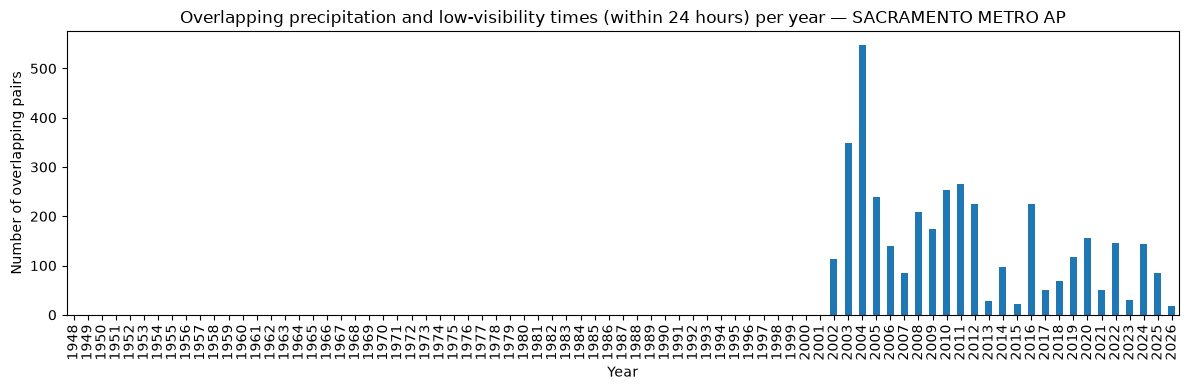

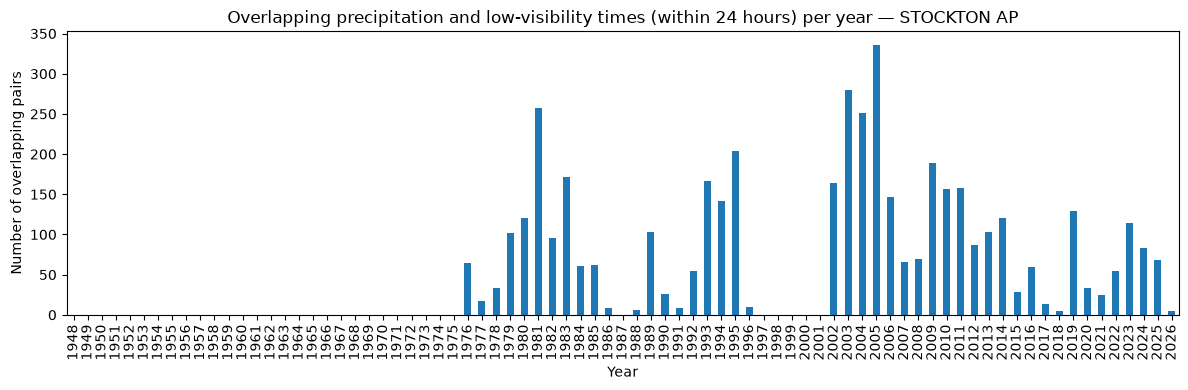

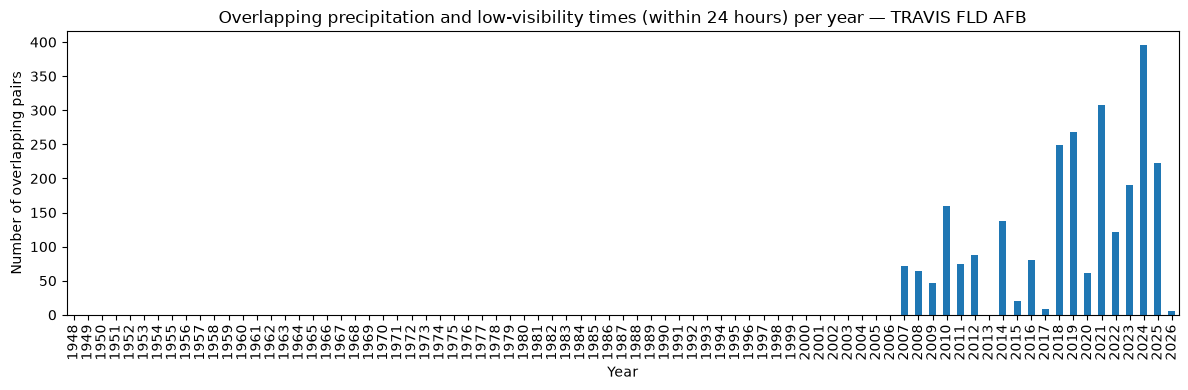

In [26]:
# this shows the number of overlapping precipitation and low-visibility times per year for each station
# this uses overlap within 24 hours
overlap_by_year = overlapping_times.copy()
overlap_by_year['year'] = pd.to_datetime(
    overlap_by_year['low_visibility_time']
).dt.year

annual_overlap_counts = overlap_by_year.groupby(['STATION', 'year']).size()

all_years = range(
    overlap_by_year['year'].min(),
    overlap_by_year['year'].max() + 1
)

for station_name in overlap_by_year['STATION'].unique():
    counts = (
        annual_overlap_counts
        .loc[station_name]
        .reindex(all_years, fill_value=0)
    )

    plt.figure(figsize=(12, 4))
    counts.plot(kind='bar')
    plt.xlabel('Year')
    plt.ylabel('Number of overlapping pairs')
    plt.title(f'Overlapping precipitation and low-visibility times (within 24 hours) per year — {station_name}')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [27]:
# Create station-day precipitation and visibility indicators
daily_obs = CV_rows[['STATION', 'DATE', 'HourlyPrecipitation', 'HourlyVisibility']].copy()
daily_obs['day'] = pd.to_datetime(daily_obs['DATE']).dt.normalize()

daily_obs['precip_valid'] = daily_obs['HourlyPrecipitation'].notna()
daily_obs['precip_event'] = daily_obs['HourlyPrecipitation'].ge(0.03)
daily_obs['vis_valid'] = daily_obs['HourlyVisibility'].notna()
daily_obs['lowvis_event'] = daily_obs['HourlyVisibility'].lt(1)

daily = (
    daily_obs.groupby(['STATION', 'day'])
    .agg(
        precip_obs=('precip_valid', 'sum'),
        precip_any=('precip_event', 'max'),
        vis_obs=('vis_valid', 'sum'),
        lowvis_any=('lowvis_event', 'max')
    )
    .reset_index()
)

# Align each day's precipitation with visibility observed the following day
next_day_vis = daily[['STATION', 'day', 'vis_obs', 'lowvis_any']].copy()
next_day_vis['day'] -= pd.Timedelta(days=1)
next_day_vis = next_day_vis.rename(columns={
    'vis_obs': 'next_day_vis_obs',
    'lowvis_any': 'lowvis_next'
})

records = daily[['STATION', 'day', 'precip_obs', 'precip_any']].merge(
    next_day_vis, on=['STATION', 'day'], how='left'
)

# Keep days with measured precipitation and measured visibility the next day
records = records[
    records['precip_obs'].gt(0) & records['next_day_vis_obs'].gt(0)
].copy()

records['precip_any'] = records['precip_any'].astype(int)
records['lowvis_next'] = records['lowvis_next'].astype(int)
records['year'] = records['day'].dt.year

# Overall station-level binary correlation (phi / Pearson correlation)
results = []

for station, group in records.groupby('STATION'):
    if group['precip_any'].nunique() == 2 and group['lowvis_next'].nunique() == 2:
        test = stats.pearsonr(group['precip_any'], group['lowvis_next'])
        correlation, p_value = test.statistic, test.pvalue
    else:
        correlation, p_value = np.nan, np.nan

    # Test whether the precipitation–low-visibility association changes over time
    group = group.copy()
    group['year_decade'] = (group['year'] - group['year'].mean()) / 10

    try:
        model = smf.glm(
            'lowvis_next ~ precip_any * year_decade',
            data=group,
            family=sm.families.Binomial()
        ).fit()

        interaction = 'precip_any:year_decade'
        interaction_or = np.exp(model.params[interaction])
        interaction_p = model.pvalues[interaction]
    except Exception:
        interaction_or, interaction_p = np.nan, np.nan

    results.append({
        'STATION': station,
        'daily_phi_correlation': correlation,
        'correlation_p_value': p_value,
        'change_in_precip_association_OR_per_decade': interaction_or,
        'trend_interaction_p_value': interaction_p,
        'eligible_station_days': len(group)
    })

station_results = pd.DataFrame(results)
station_results

,STATION,daily_phi_correlation,correlation_p_value,change_in_precip_association_OR_per_decade,trend_interaction_p_value,eligible_station_days
0,BAKERSFIELD AP,0.008653,2.978737e-01,1.054887,0.055217,14476
1,BEALE AFB,0.073572,8.670616e-13,1.916063,0.000013,9422
2,CASTLE AFB,-0.010520,2.875993e-01,1.217741,0.665851,10220
3,FRESNO YOSEMITE INTL,-0.050930,1.847764e-08,1.016729,0.514667,12188
4,LEMOORE REEVES NAS,0.023771,1.994278e-02,0.838705,0.149611,9586
5,RED BLUFF MUNI AP,0.015338,8.904008e-02,0.936449,0.166617,12293
6,REDDING AP,0.101102,8.418045e-20,1.047687,0.509272,8076
7,SACRAMENTO AP ASOS,-0.045639,6.371295e-08,1.077618,0.000492,14029
8,SACRAMENTO MATHER AFB,0.006660,4.772863e-01,1.022620,0.942338,11388
9,SACRAMENTO MCCLELLAN AFB,0.016468,8.347936e-02,10.932291,0.304315,11048


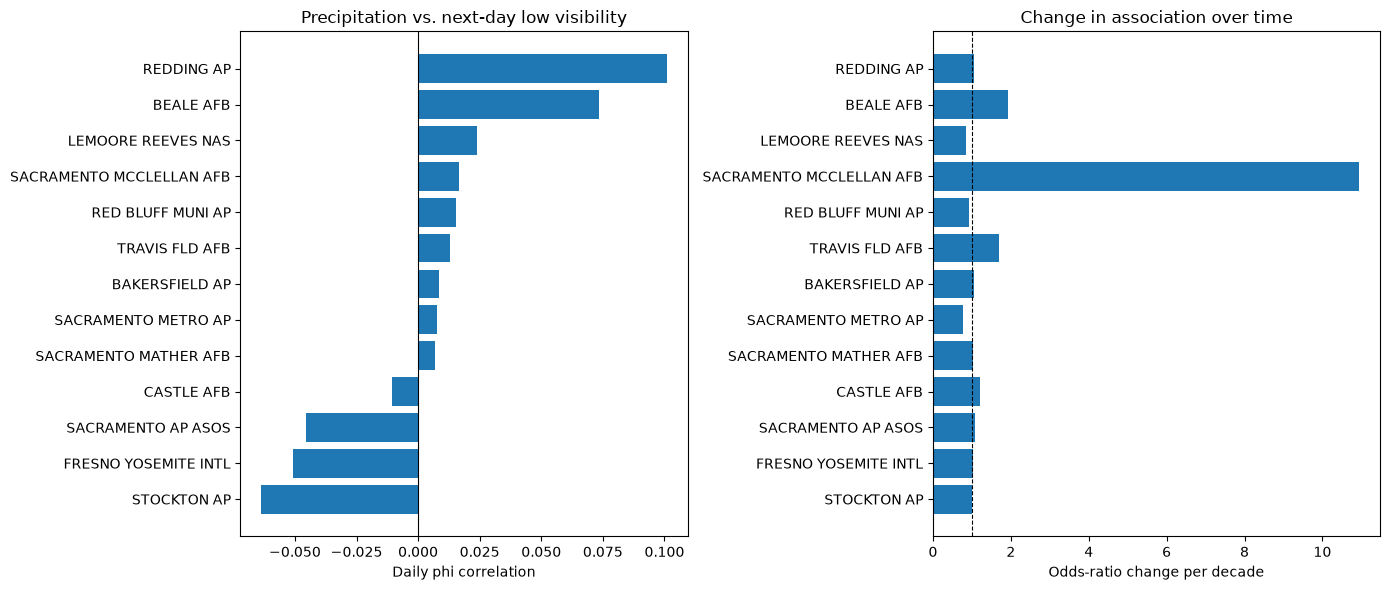

In [28]:
# Compare station-level precipitation/visibility associations
plot_data = station_results.sort_values('daily_phi_correlation')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(plot_data['STATION'], plot_data['daily_phi_correlation'])
axes[0].axvline(0, color='black', linewidth=0.8)
# daily phi correlation shows us
# the strength and direction of the association between precipitation and next-day low visibility
axes[0].set_xlabel('Daily phi correlation')
# higher values (closer to 1) indicate a stronger positive association
# lower values (closer to -1) indicate a negative association
axes[0].set_title('Precipitation vs. next-day low visibility')

axes[1].barh(
    plot_data['STATION'],
    plot_data['change_in_precip_association_OR_per_decade']
)
axes[1].axvline(1, color='black', linestyle='--', linewidth=0.8)
# odds-ratio of change per decade means no change if equal to 1
axes[1].set_xlabel('Odds-ratio change per decade')
# change in association over time means the odds of low visibility following precipitation
# are increasing or decreasing over decades
axes[1].set_title('Change in association over time')

plt.tight_layout()
plt.show()

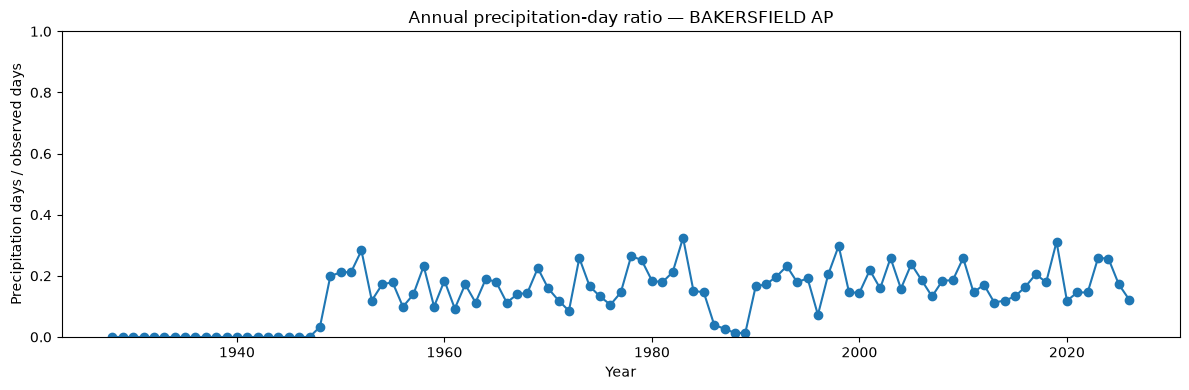

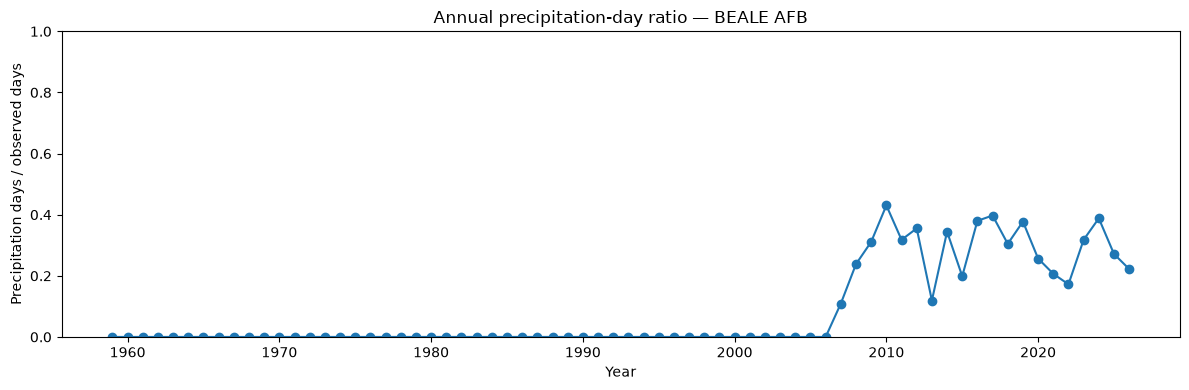

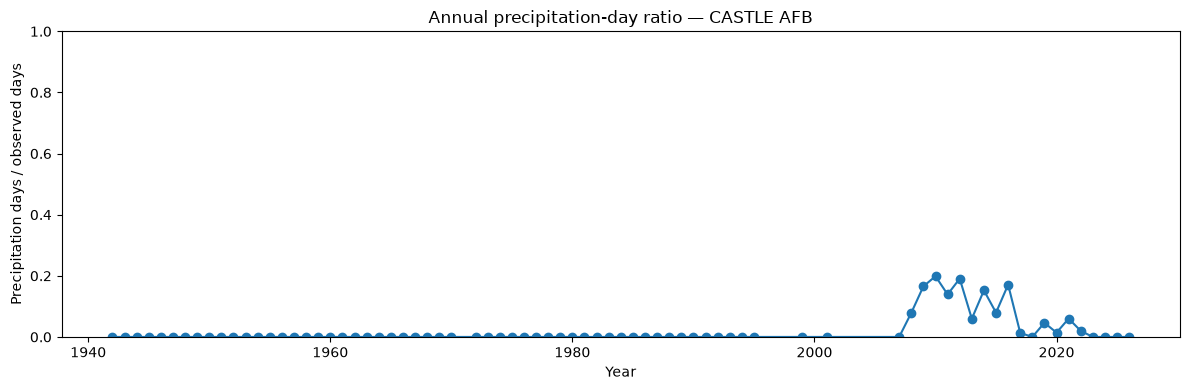

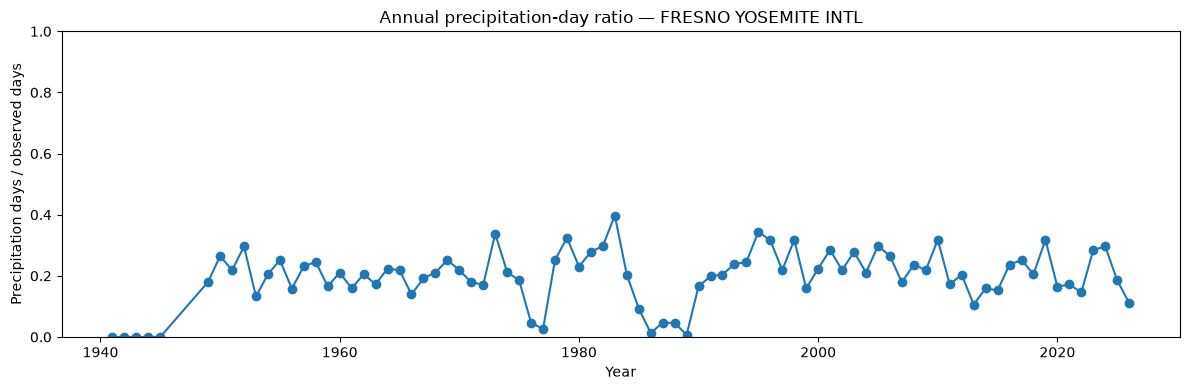

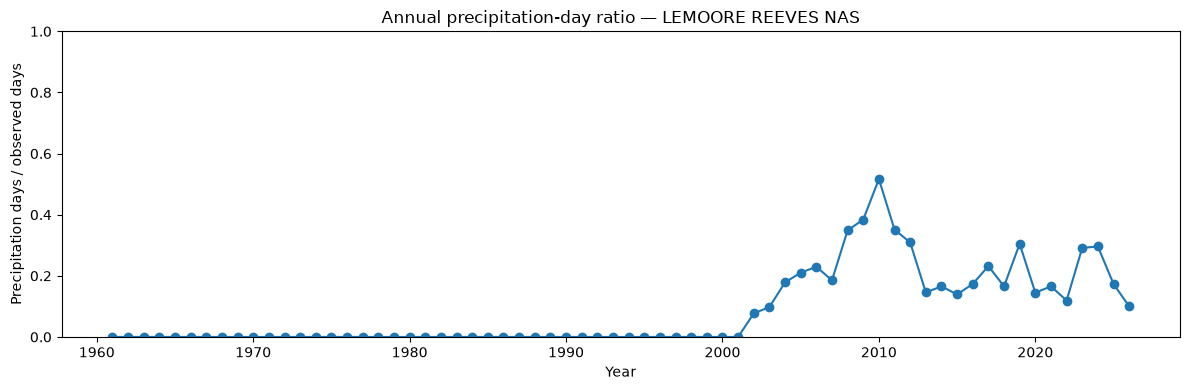

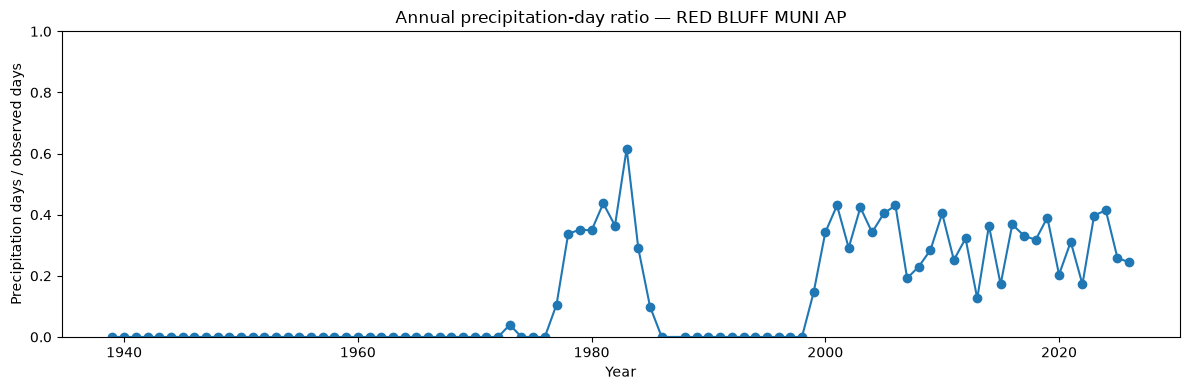

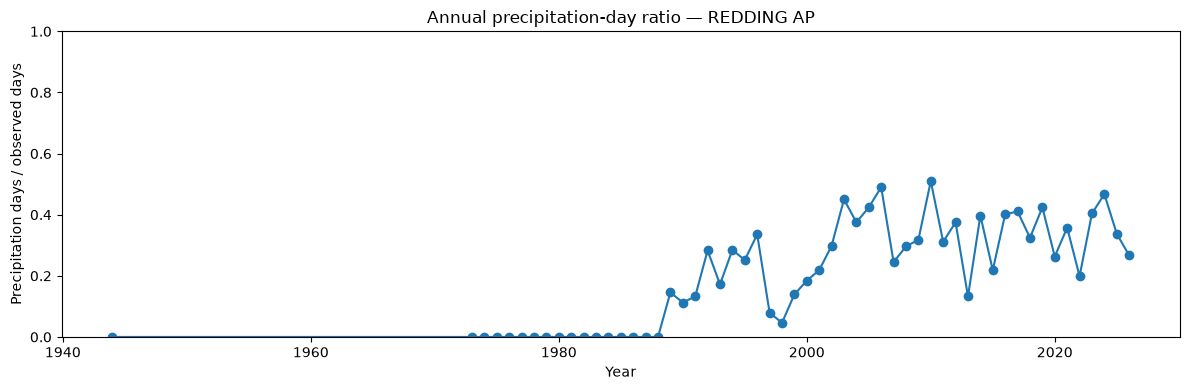

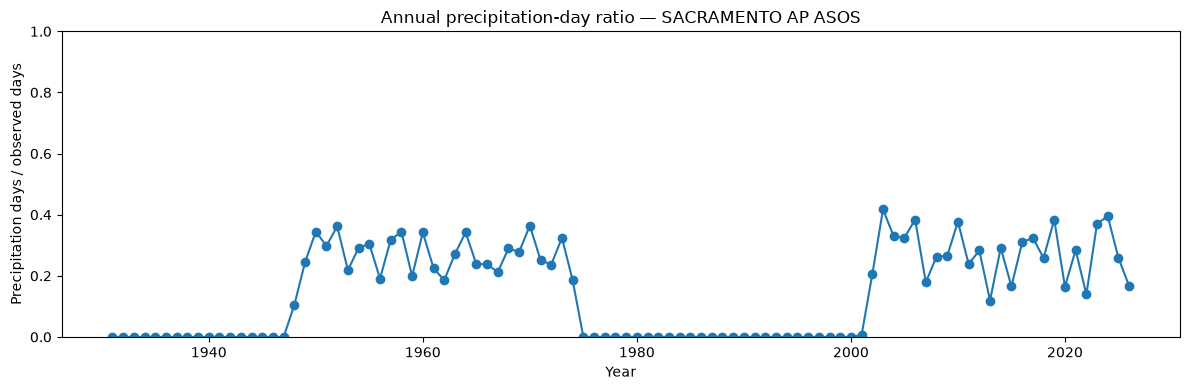

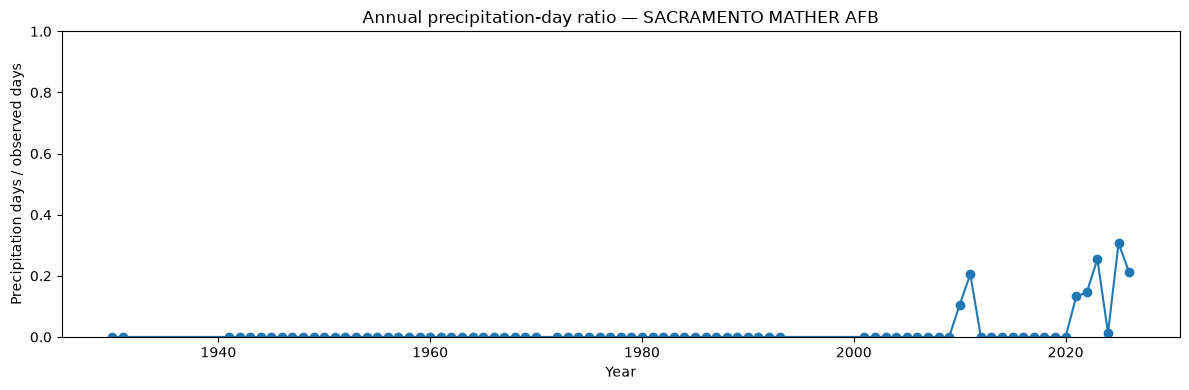

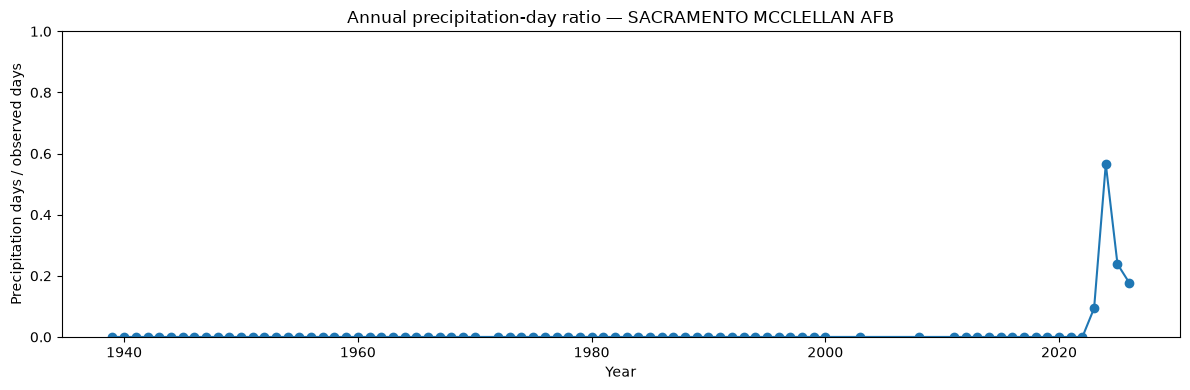

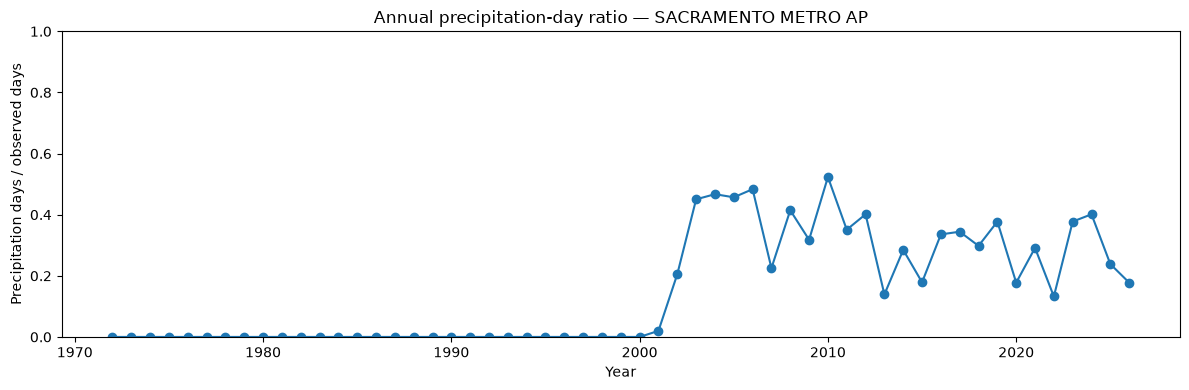

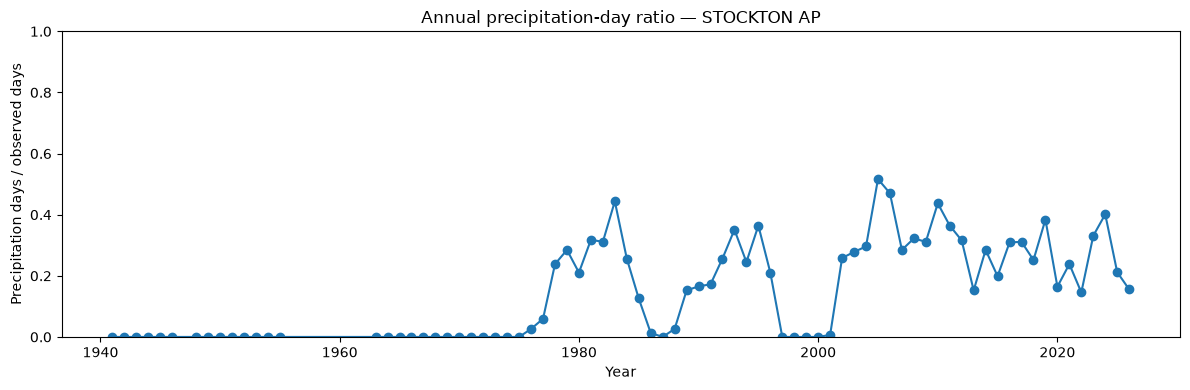

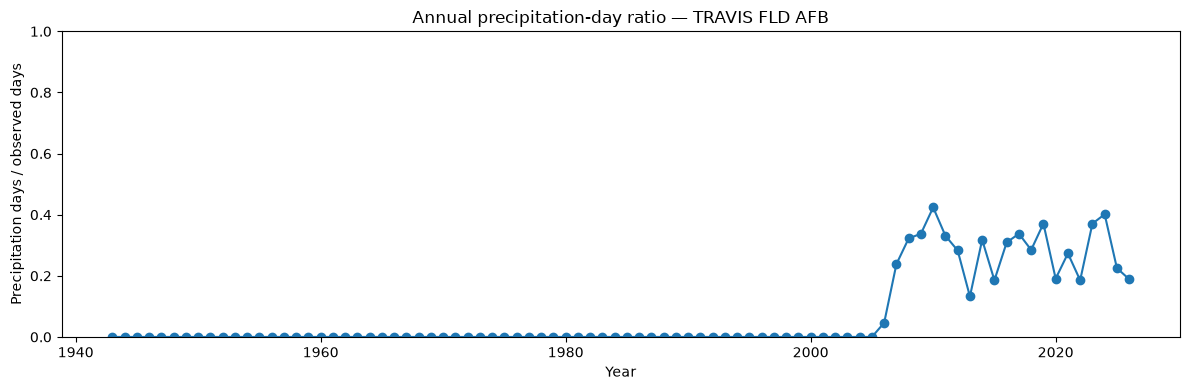

In [29]:
# Count unique station-days in each dataset
cv_days = CV_rows[['STATION', 'year', 'month', 'day']].drop_duplicates()
precip_days = CV_precip_rows[['STATION', 'year', 'month', 'day']].drop_duplicates()

cv_annual_days = cv_days.groupby(['STATION', 'year']).size().rename('cv_days')
precip_annual_days = precip_days.groupby(['STATION', 'year']).size().rename('precip_days')

# Include years with no precipitation days and calculate the ratio of precipitation days to observed days
annual_day_ratio = cv_annual_days.to_frame().join(precip_annual_days)
annual_day_ratio['precip_days'] = annual_day_ratio['precip_days'].fillna(0)
annual_day_ratio['day_ratio'] = annual_day_ratio['precip_days'] / annual_day_ratio['cv_days']

# Plot the ratio by year for each station
for station_name, station_data in annual_day_ratio.groupby(level='STATION'):
    station_data = station_data.droplevel('STATION').sort_index()

    plt.figure(figsize=(12, 4))
    plt.plot(station_data.index, station_data['day_ratio'], marker='o')
    plt.xlabel('Year')
    plt.ylabel('Precipitation days / observed days')
    plt.title(f'Annual precipitation-day ratio — {station_name}')
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [10]:
# Assign each row to a seven-day bin within its month
def add_month_week(df):
    result = df.copy()
    result['DATE'] = pd.to_datetime(result['DATE'])
    result['year_month'] = result['DATE'].dt.to_period('M')
    result['week_in_month'] = ((result['DATE'].dt.day - 1) // 7) + 1
    return result

# Count foggy rows within all weeks that have visibility observations
CV_vis_rows = CV_rows.loc[(CV_rows['HourlyVisibility'].notna() & CV_rows['HourlyPrecipitation'] <= 0.03)].copy()
vis_weekly = add_month_week(CV_vis_rows)
# add column indicating foggy conditions
vis_weekly['foggy'] = vis_weekly['HourlyVisibility'].lt(1)

weekly_counts = (
    vis_weekly.groupby(['STATION', 'year_month', 'week_in_month'])
    .agg(foggy_rows=('foggy', 'sum'))
    .reset_index()
)

# Count rainy rows and align them with the visibility-observed weeks
precip_weekly = add_month_week(CV_precip_rows)
rain_counts = (
    precip_weekly.groupby(['STATION', 'year_month', 'week_in_month'])
    .size()
    .rename('rainy_rows')
    .reset_index()
)

weekly_counts = weekly_counts.merge(
    rain_counts,
    on=['STATION', 'year_month', 'week_in_month'],
    how='left'
)
weekly_counts['rainy_rows'] = weekly_counts['rainy_rows'].fillna(0).astype(int)

# Calculate the correlation for each station
correlation_results = []

for station, group in weekly_counts.groupby('STATION'):
    if len(group) >= 2 and group['rainy_rows'].nunique() > 1 and group['foggy_rows'].nunique() > 1:
        test = stats.pearsonr(group['rainy_rows'], group['foggy_rows'])
        correlation, p_value = test.statistic, test.pvalue
    else:
        correlation, p_value = np.nan, np.nan

    correlation_results.append({
        'STATION': station,
        'weekly_bins': len(group),
        'pearson_correlation': correlation,
        'p_value': p_value
    })

station_weekly_correlations = pd.DataFrame(correlation_results)
display(station_weekly_correlations)

,STATION,weekly_bins,pearson_correlation,p_value
0,BAKERSFIELD AP,2379,-0.014783,0.471088
1,BEALE AFB,1577,0.051060,0.042623
2,CASTLE AFB,1680,0.009784,0.688624
3,FRESNO YOSEMITE INTL,1968,-0.083338,0.000215
4,LEMOORE REEVES NAS,1574,0.121421,0.000001
5,RED BLUFF MUNI AP,2075,-0.000104,0.996210
6,REDDING AP,1306,0.077670,0.004978
7,SACRAMENTO AP ASOS,2296,-0.016449,0.430815
8,SACRAMENTO MATHER AFB,1850,0.035446,0.127501
9,SACRAMENTO MCCLELLAN AFB,1793,-0.010113,0.668713


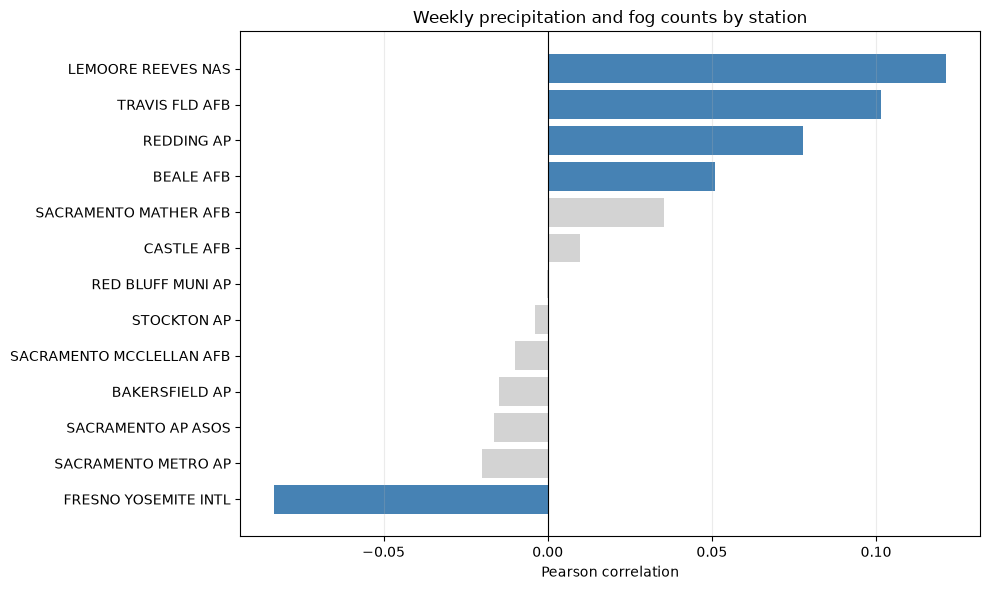

In [11]:
plot_data = station_weekly_correlations.sort_values('pearson_correlation')
colors = np.where(plot_data['p_value'] < 0.05, 'steelblue', 'lightgray')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data['STATION'], plot_data['pearson_correlation'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson correlation')
ax.set_title('Weekly precipitation and fog counts by station')
ax.grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.show()

In [12]:
annual_event_rows = CV_rows.copy()

annual_event_rows['precip_event'] = (
    annual_event_rows['HourlyPrecipitation'].ge(0.03)
)
annual_event_rows['fog_event'] = (
    annual_event_rows['HourlyVisibility'].lt(1)
    & annual_event_rows['HourlyPrecipitation'].lt(0.03)
)

yearly_counts = (
    annual_event_rows
    .groupby(['STATION', 'year'])
    .agg(
        yearly_precip_count=('precip_event', 'sum'),
        yearly_fog_count=('fog_event', 'sum')
    )
    .reset_index()
)

annual_count_correlation_results = []

for station, group in yearly_counts.groupby('STATION'):
    if (
        len(group) >= 2
        and group['yearly_precip_count'].nunique() > 1
        and group['yearly_fog_count'].nunique() > 1
    ):
        test = stats.pearsonr(
            group['yearly_precip_count'],
            group['yearly_fog_count']
        )
        r, p_value = test.statistic, test.pvalue
    else:
        r, p_value = np.nan, np.nan

    annual_count_correlation_results.append({
        'STATION': station,
        'years': len(group),
        'pearson_correlation': r,
        'p_value': p_value
    })

annual_count_correlations = pd.DataFrame(annual_count_correlation_results)
display(annual_count_correlations.sort_values('p_value'))

,STATION,years,pearson_correlation,p_value
12,TRAVIS FLD AFB,84,0.631139,1.229165e-10
11,STOCKTON AP,78,0.441513,5.202001e-05
8,SACRAMENTO MATHER AFB,80,0.421063,1.005404e-04
4,LEMOORE REEVES NAS,66,0.443597,1.910771e-04
1,BEALE AFB,68,0.345327,3.924870e-03
6,REDDING AP,55,0.256242,5.897825e-02
7,SACRAMENTO AP ASOS,96,0.172808,9.224431e-02
0,BAKERSFIELD AP,99,0.144098,1.547394e-01
2,CASTLE AFB,75,0.165365,1.562394e-01
9,SACRAMENTO MCCLELLAN AFB,79,0.100146,3.798682e-01


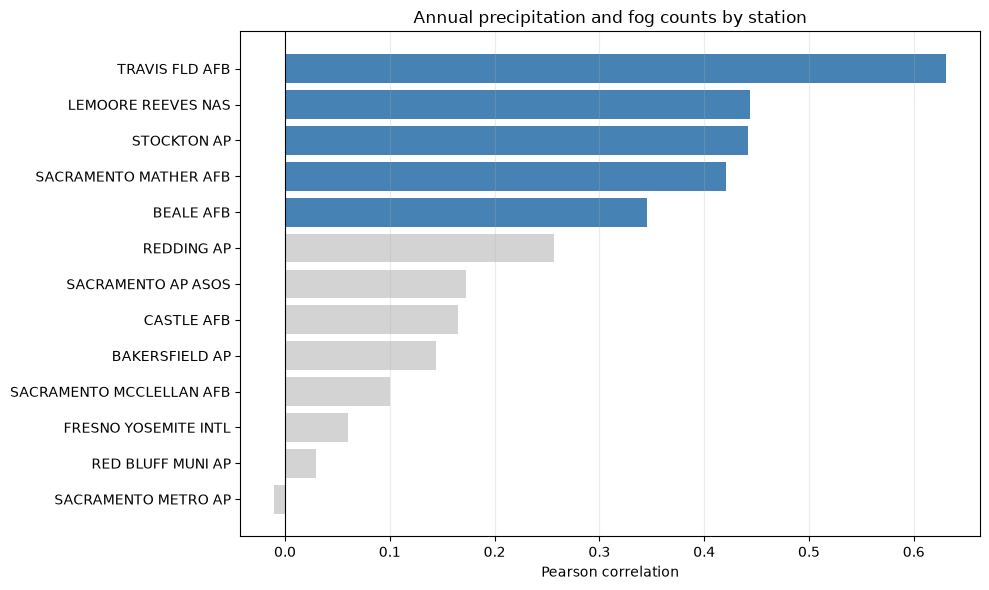

In [13]:
plot_data = annual_count_correlations.sort_values('pearson_correlation')
colors = np.where(plot_data['p_value'] < 0.05, 'steelblue', 'lightgray')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_data['STATION'], plot_data['pearson_correlation'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson correlation')
ax.set_title('Annual precipitation and fog counts by station')
ax.grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.show()

In [30]:
from statsmodels.stats.multitest import multipletests

trend_data = annual_day_ratio.reset_index()

# Exclude the latest year because it may be incomplete
latest_year = trend_data['year'].max()
trend_data = trend_data[trend_data['year'] < latest_year].copy()

trend_results = []

for station, group in trend_data.groupby('STATION'):
    group = group.dropna(subset=['cv_days', 'precip_days']).copy()
    group = group[group['cv_days'] > 0]

    # Scale time so the coefficient represents a change per decade
    group['year_decade'] = (group['year'] - group['year'].mean()) / 10
    proportion = group['precip_days'] / group['cv_days']

    try:
        X = sm.add_constant(group['year_decade'])
        model = sm.GLM(
            proportion,
            X,
            family=sm.families.Binomial(),
            freq_weights=group['cv_days']
        ).fit()

        beta = model.params['year_decade']
        ci_low, ci_high = model.conf_int().loc['year_decade']

        trend_results.append({
            'STATION': station,
            'odds_ratio_per_decade': np.exp(beta),
            'ci_low': np.exp(ci_low),
            'ci_high': np.exp(ci_high),
            'p_value': model.pvalues['year_decade'],
            'years': len(group)
        })
    except Exception as exc:
        print(f"Could not fit trend for {station}: {exc}")

trend_results = pd.DataFrame(trend_results)

if not trend_results.empty:
    trend_results['fdr_p_value'] = multipletests(
        trend_results['p_value'], method='fdr_bh'
    )[1]
    trend_results['significant_fdr'] = trend_results['fdr_p_value'] < 0.05
    trend_results['direction'] = np.where(
        trend_results['odds_ratio_per_decade'] > 1, 'increasing', 'decreasing'
    )
    display(trend_results.sort_values('fdr_p_value'))

,STATION,odds_ratio_per_decade,ci_low,ci_high,p_value,years,fdr_p_value,significant_fdr,direction
5,RED BLUFF MUNI AP,1.620652,1.576253,1.666303,2.277938e-254,86,2.961319e-253,True,increasing
10,SACRAMENTO METRO AP,2.395830,2.260430,2.539341,1.860128e-190,54,1.209083e-189,True,increasing
11,STOCKTON AP,1.528820,1.485651,1.573243,1.669249e-185,77,7.233413e-185,True,increasing
12,TRAVIS FLD AFB,3.384280,3.112666,3.679595,2.039442e-179,83,6.628185e-179,True,increasing
6,REDDING AP,1.886163,1.805551,1.970375,2.519801e-178,54,6.551482e-178,True,increasing
1,BEALE AFB,3.494303,3.200346,3.815260,2.300230e-171,67,4.983831e-171,True,increasing
4,LEMOORE REEVES NAS,2.519075,2.354168,2.695533,1.385921e-157,65,2.573853e-157,True,increasing
0,BAKERSFIELD AP,1.180013,1.159228,1.201171,1.872619e-74,98,3.043006e-74,True,increasing
7,SACRAMENTO AP ASOS,1.135529,1.115778,1.155629,9.507507e-46,95,1.373307e-45,True,increasing
2,CASTLE AFB,2.077303,1.877317,2.298593,1.737804e-45,74,2.259145e-45,True,increasing


In [31]:
# make the line fit a linear trend only for stations with significant trends

trend_data_since_1980 = annual_day_ratio.reset_index()
latest_year_since_1980 = trend_data_since_1980['year'].max()

trend_data_since_1980 = trend_data_since_1980[
    (trend_data_since_1980['year'] >= 1980) &
    (trend_data_since_1980['year'] < latest_year_since_1980)
].copy()

trend_results_since_1980 = []

for station, group in trend_data_since_1980.groupby('STATION'):
    group = group.dropna(subset=['cv_days', 'precip_days']).copy()
    group = group[group['cv_days'] > 0]

    group['year_decade'] = (group['year'] - group['year'].mean()) / 10
    proportion = group['precip_days'] / group['cv_days']

# fit a GLM to the proportion of precipitation days, using the number of observed days as weights
# Change this to fit only a linear trend for stations with significant trends
    try:
        X = sm.add_constant(group['year_decade'])
        model = sm.GLM(
            proportion,
            X,
            family=sm.families.Binomial(),
            freq_weights=group['cv_days']
        ).fit()

        beta = model.params['year_decade']
        ci_low, ci_high = model.conf_int().loc['year_decade']

        trend_results_since_1980.append({
            'STATION': station,
            'odds_ratio_per_decade': np.exp(beta),
            'ci_low': np.exp(ci_low),
            'ci_high': np.exp(ci_high),
            'p_value': model.pvalues['year_decade'],
            'years': len(group)
        })
    except Exception as exc:
        print(f"Could not fit trend for {station}: {exc}")

trend_results_since_1980 = pd.DataFrame(trend_results_since_1980)

if not trend_results_since_1980.empty:
    trend_results_since_1980['fdr_p_value'] = multipletests(
        trend_results_since_1980['p_value'], method='fdr_bh'
    )[1]
    trend_results_since_1980['significant_fdr'] = (
        trend_results_since_1980['fdr_p_value'] < 0.05
    )
    trend_results_since_1980['direction'] = np.where(
        trend_results_since_1980['odds_ratio_per_decade'] > 1,
        'increasing',
        'decreasing'
    )
    display(trend_results_since_1980.sort_values('fdr_p_value'))

,STATION,odds_ratio_per_decade,ci_low,ci_high,p_value,years,fdr_p_value,significant_fdr,direction
10,SACRAMENTO METRO AP,2.280900,2.145898,2.424396,1.311236e-154,46,1.704607e-153,True,increasing
12,TRAVIS FLD AFB,3.268675,2.993614,3.569009,1.109772e-153,46,7.213516e-153,True,increasing
1,BEALE AFB,3.393328,3.097003,3.718005,2.204037e-151,46,9.550828e-151,True,increasing
7,SACRAMENTO AP ASOS,2.397796,2.241980,2.564442,1.496395e-143,46,4.863284e-143,True,increasing
6,REDDING AP,1.725528,1.646209,1.808668,2.740988e-114,46,7.126569e-114,True,increasing
4,LEMOORE REEVES NAS,2.342127,2.175853,2.521106,1.337148e-113,46,2.897155e-113,True,increasing
8,SACRAMENTO MATHER AFB,6.058140,4.519540,8.120529,1.929499e-33,39,3.583355e-33,True,increasing
9,SACRAMENTO MCCLELLAN AFB,13633.437217,2651.970978,70087.724162,4.328216e-30,38,7.033352e-30,True,increasing
2,CASTLE AFB,1.762711,1.564220,1.986389,1.406347e-20,37,2.031390e-20,True,increasing
5,RED BLUFF MUNI AP,1.215865,1.163726,1.270340,2.319696e-18,45,3.015605e-18,True,increasing


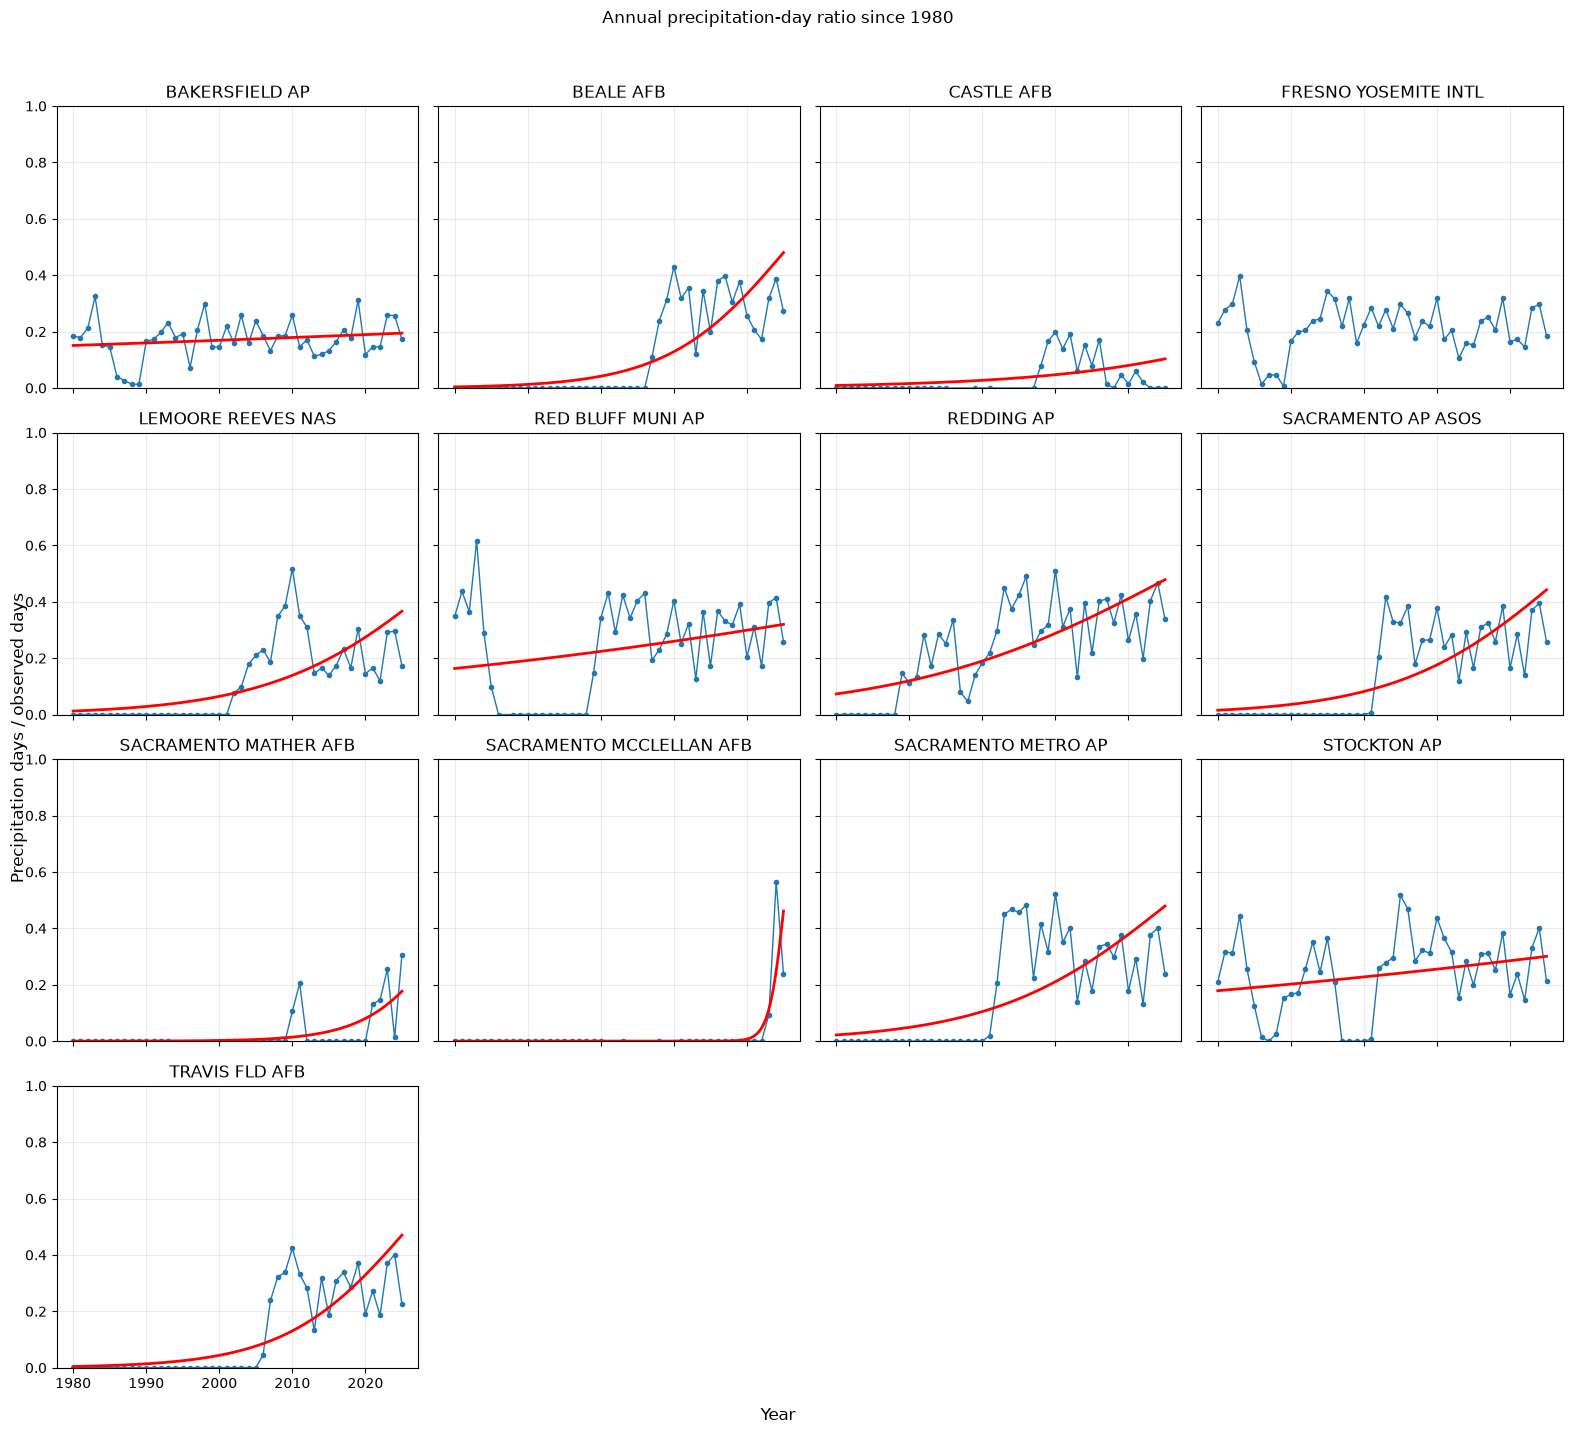

In [32]:
# make this fitting a linear trend only for stations with significant trends
stations = trend_data_since_1980['STATION'].unique()
ncols = 4
nrows = int(np.ceil(len(stations) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(16, 3.5 * nrows),
    sharex=True, sharey=True
)
axes = np.asarray(axes).ravel()

significant_stations = set(
    trend_results_since_1980.loc[
        trend_results_since_1980['significant_fdr'], 'STATION'
    ]
)

for ax, station_name in zip(axes, stations):
    station_data = (
        trend_data_since_1980[
            trend_data_since_1980['STATION'] == station_name
        ]
        .dropna(subset=['year', 'cv_days', 'precip_days'])
        .sort_values('year')
        .copy()
    )

    ax.plot(
        station_data['year'], station_data['day_ratio'],
        marker='o', markersize=3, linewidth=1, label='Observed'
    )

    if station_name in significant_stations:
        station_data['year_decade'] = (
            station_data['year'] - station_data['year'].mean()
        ) / 10
        X = sm.add_constant(station_data['year_decade'])

        model = sm.GLM(
            station_data['precip_days'] / station_data['cv_days'],
            X,
            family=sm.families.Binomial(),
            freq_weights=station_data['cv_days']
        ).fit()

        line_years = np.linspace(
            station_data['year'].min(), station_data['year'].max(), 200
        )
        line_x = pd.DataFrame({
            'const': 1.0,
            'year_decade': (line_years - station_data['year'].mean()) / 10
        })

        ax.plot(
            line_years, model.predict(line_x),
            color='red', linewidth=2, label='Significant trend (FDR < 0.05)'
        )

    ax.set_title(station_name)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

for ax in axes[len(stations):]:
    ax.set_visible(False)

fig.supxlabel('Year')
fig.supylabel('Precipitation days / observed days')
fig.suptitle('Annual precipitation-day ratio since 1980', y=1.02)
fig.tight_layout()
plt.show()